# Air Quality Analysis and Carbon Monoxide (CO) Concentration Prediction Using Data Mining Techniques

## CA2 – Data Mining and Business Intelligence

### Objective
To analyze historical air quality data and develop machine learning models for predicting carbon monoxide (CO) concentration using sensor responses and environmental parameters.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Downloading the official UCI Air Quality dataset

dataset_url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

response = urlopen(dataset_url, timeout=60).read()

with ZipFile(BytesIO(response)) as zip_file:

    # Locate the CSV file inside the downloaded ZIP
    csv_file = next(
        name for name in zip_file.namelist()
        if name.lower().endswith("airqualityuci.csv")
    )

    # Read the CSV file
    with zip_file.open(csv_file) as file:
        df_raw = pd.read_csv(
            file,
            sep=';',
            decimal=','
        )

print("Dataset downloaded and loaded successfully!")
print("Original dataset shape:", df_raw.shape)

Dataset downloaded and loaded successfully!
Original dataset shape: (9471, 17)


In [3]:
# Displaying the original dataset

print("First 5 records:")
display(df_raw.head())

print("\nLast 5 records:")
display(df_raw.tail())

print("\nOriginal column names:")
print(df_raw.columns.tolist())

First 5 records:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN



Last 5 records:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Original column names:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']


In [4]:
# Removing completely empty columns

empty_columns = df_raw.columns[df_raw.isna().all()].tolist()

df = df_raw.drop(columns=empty_columns).copy()

# Removing unnecessary spaces from column names
df.columns = df.columns.str.strip()

print("Completely empty columns removed:", empty_columns)
print("Final dataset shape:", df.shape)

Completely empty columns removed: ['Unnamed: 15', 'Unnamed: 16']
Final dataset shape: (9471, 15)


In [5]:
# Checking column names

print("Dataset columns:")
for column in df.columns:
    print(column)

# Checking data types and non-null counts
print("\nDataset information:")
df.info()

Dataset columns:
Date
Time
CO(GT)
PT08.S1(CO)
NMHC(GT)
C6H6(GT)
PT08.S2(NMHC)
NOx(GT)
PT08.S3(NOx)
NO2(GT)
PT08.S4(NO2)
PT08.S5(O3)
T
RH
AH

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 no

In [6]:
# Generating descriptive statistics

print("Statistical summary of the dataset:")

display(df.describe(include='all').T)

Statistical summary of the dataset:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,9357,391,03/04/2005,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18.00.00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),9357.0,NaN,NaN,NaN,-34.207524,77.65717,-200.0,0.6,1.5,2.6,11.9
PT08.S1(CO),9357.0,NaN,NaN,NaN,1048.990061,329.83271,-200.0,921.0,1053.0,1221.0,2040.0
NMHC(GT),9357.0,NaN,NaN,NaN,-159.090093,139.789093,-200.0,-200.0,-200.0,-200.0,1189.0
C6H6(GT),9357.0,NaN,NaN,NaN,1.865683,41.380206,-200.0,4.0,7.9,13.6,63.7
PT08.S2(NMHC),9357.0,NaN,NaN,NaN,894.595276,342.333252,-200.0,711.0,895.0,1105.0,2214.0
NOx(GT),9357.0,NaN,NaN,NaN,168.616971,257.433866,-200.0,50.0,141.0,284.0,1479.0
PT08.S3(NOx),9357.0,NaN,NaN,NaN,794.990168,321.993552,-200.0,637.0,794.0,960.0,2683.0
NO2(GT),9357.0,NaN,NaN,NaN,58.148873,126.940455,-200.0,53.0,96.0,133.0,340.0


In [7]:
# Checking standard missing values

print("Missing values in each column:")

display(df.isnull().sum().to_frame(name='Missing Values'))

Missing values in each column:


,Missing Values
Date,114
Time,114
CO(GT),114
PT08.S1(CO),114
NMHC(GT),114
C6H6(GT),114
PT08.S2(NMHC),114
NOx(GT),114
PT08.S3(NOx),114
NO2(GT),114


In [8]:
# Counting special missing-value codes

numeric_columns = df.select_dtypes(include=np.number).columns

special_missing = df[numeric_columns].eq(-200).sum()

print("Number of -200 values in each numerical column:")

display(special_missing.to_frame(name='-200 Values'))

Number of -200 values in each numerical column:


,-200 Values
CO(GT),1683
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),366
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642
PT08.S4(NO2),366
PT08.S5(O3),366


In [9]:
# Checking the date and time information

datetime_check = pd.to_datetime(
    df['Date'].astype(str).str.strip() + ' ' +
    df['Time'].astype(str).str.strip(),
    format='%d/%m/%Y %H.%M.%S',
    errors='coerce'
)

print("Earliest observation:", datetime_check.min())
print("Latest observation:", datetime_check.max())

print("Invalid date/time records:", datetime_check.isna().sum())

print("Chronological order:", datetime_check.is_monotonic_increasing)

Earliest observation: 2004-03-10 18:00:00
Latest observation: 2005-04-04 14:00:00
Invalid date/time records: 114
Chronological order: False


In [10]:
# Checking duplicate records

print("Duplicate rows:", df.duplicated().sum())

# Checking the availability of the target variable

co_values = pd.to_numeric(df['CO(GT)'], errors='coerce')

valid_co = co_values.notna() & (co_values != -200)

print("\nTarget variable: CO(GT)")
print("Total observations:", len(df))
print("Valid CO observations:", valid_co.sum())
print("Missing CO observations:", (~valid_co).sum())

Duplicate rows: 113

Target variable: CO(GT)
Total observations: 9471
Valid CO observations: 7674
Missing CO observations: 1797


In [11]:
# Saving the loaded dataset for use in subsequent phases

df.to_csv('AirQuality_Initial.csv', index=False)

print("Initial dataset saved successfully!")

Initial dataset saved successfully!


In [12]:
# Investigating the extra rows

print("Total rows:", len(df))

print("Completely empty rows:", df.isna().all(axis=1).sum())

print("Rows with missing Date or Time:",
      df[['Date', 'Time']].isna().any(axis=1).sum())

print("Rows containing at least one value:",
      df.notna().any(axis=1).sum())

print("\nLast 10 records:")
display(df.tail(10))

Total rows: 9471
Completely empty rows: 114
Rows with missing Date or Time: 114
Rows containing at least one value: 9357

Last 10 records:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
9461,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9462,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9463,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9464,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9465,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Removing completely empty rows

df = df.dropna(how='all').reset_index(drop=True)

print("Dataset shape after removing empty rows:", df.shape)
print("Remaining completely empty rows:", df.isna().all(axis=1).sum())

# Displaying the first and last records
display(df.head())
display(df.tail())

Dataset shape after removing empty rows: (9357, 15)
Remaining completely empty rows: 0


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
9352,04/04/2005,10.00.00,3.1,1314.0,-200.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
9353,04/04/2005,11.00.00,2.4,1163.0,-200.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
9354,04/04/2005,12.00.00,2.4,1142.0,-200.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406
9355,04/04/2005,13.00.00,2.1,1003.0,-200.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139
9356,04/04/2005,14.00.00,2.2,1071.0,-200.0,11.9,1047.0,265.0,654.0,168.0,1129.0,816.0,28.5,13.1,0.5028


In [14]:
# Saving the updated initial dataset

df.to_csv('AirQuality_Initial.csv', index=False)

print("Updated initial dataset saved successfully!")

Updated initial dataset saved successfully!


# Phase 2 — Data Cleaning and Preprocessing

In [15]:
# Creating a backup of the Phase 1 dataset

df_phase1 = df.copy()

print("Phase 1 dataset backup created successfully!")
print("Dataset shape:", df_phase1.shape)

Phase 1 dataset backup created successfully!
Dataset shape: (9357, 15)


In [16]:
# Identifying special missing values

numeric_columns = df_phase1.select_dtypes(include=np.number).columns

missing_200 = df_phase1[numeric_columns].eq(-200).sum()

print("Special missing values (-200) in each column:")

display(missing_200.to_frame(name='Missing Values'))

Special missing values (-200) in each column:


,Missing Values
CO(GT),1683
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),366
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642
PT08.S4(NO2),366
PT08.S5(O3),366


In [17]:
# Replacing -200 with NaN

df_clean = df_phase1.copy()

df_clean[numeric_columns] = df_clean[numeric_columns].replace(-200, np.nan)

print("Special missing values replaced successfully!")

print("Remaining -200 values:",
      int(df_clean[numeric_columns].eq(-200).sum().sum()))

print("Total missing values after replacement:",
      int(df_clean[numeric_columns].isna().sum().sum()))

Special missing values replaced successfully!
Remaining -200 values: 0
Total missing values after replacement: 16701


In [18]:
# Combining Date and Time into a DateTime column

date_time = (
    df_clean['Date'].astype(str).str.strip()
    + ' '
    + df_clean['Time'].astype(str).str.strip()
)

df_clean['DateTime'] = pd.to_datetime(
    date_time,
    format='%d/%m/%Y %H.%M.%S',
    errors='coerce'
)

print("DateTime column created successfully!")

print("Invalid DateTime records:", df_clean['DateTime'].isna().sum())

print("\nEarliest observation:", df_clean['DateTime'].min())
print("Latest observation:", df_clean['DateTime'].max())

DateTime column created successfully!
Invalid DateTime records: 0

Earliest observation: 2004-03-10 18:00:00
Latest observation: 2005-04-04 14:00:00


In [19]:
# Sorting the observations chronologically

df_clean = df_clean.sort_values(
    by='DateTime'
).reset_index(drop=True)

print("Dataset sorted chronologically!")

print("Chronological order:",
      df_clean['DateTime'].is_monotonic_increasing)

# Checking duplicate timestamps

duplicate_timestamps = df_clean['DateTime'].duplicated().sum()

print("Duplicate timestamps:", duplicate_timestamps)

Dataset sorted chronologically!
Chronological order: True
Duplicate timestamps: 0


In [20]:
# Checking missing target values

target_column = 'CO(GT)'

missing_target = df_clean[target_column].isna().sum()

print("Missing CO(GT) values:", missing_target)
print("Valid CO(GT) values:", df_clean[target_column].notna().sum())

# Removing rows where the target variable is missing

df_model_base = df_clean.dropna(
    subset=[target_column]
).copy().reset_index(drop=True)

print("\nDataset shape after removing missing target values:",
      df_model_base.shape)

print("Remaining missing target values:",
      df_model_base[target_column].isna().sum())

Missing CO(GT) values: 1683
Valid CO(GT) values: 7674

Dataset shape after removing missing target values: (7674, 16)
Remaining missing target values: 0


In [21]:
# Selecting input features and target variable

feature_columns = [
    'PT08.S1(CO)',
    'PT08.S2(NMHC)',
    'PT08.S3(NOx)',
    'PT08.S4(NO2)',
    'PT08.S5(O3)',
    'T',
    'RH',
    'AH'
]

target_column = 'CO(GT)'

print("Selected input features:")
for feature in feature_columns:
    print(feature)

print("\nTarget variable:", target_column)
print("\nTotal input features:", len(feature_columns))

Selected input features:
PT08.S1(CO)
PT08.S2(NMHC)
PT08.S3(NOx)
PT08.S4(NO2)
PT08.S5(O3)
T
RH
AH

Target variable: CO(GT)

Total input features: 8


In [22]:
# Creating the modeling dataset

model_data = df_model_base[
    ['DateTime'] + feature_columns + [target_column]
].copy()

# Ensuring all model features and target are numeric
for column in feature_columns + [target_column]:
    model_data[column] = pd.to_numeric(
        model_data[column],
        errors='coerce'
    )

print("Modeling dataset created successfully!")

print("Dataset shape:", model_data.shape)

print("\nFirst 5 records:")
display(model_data.head())

print("\nColumn data types:")
display(model_data.dtypes.to_frame(name='Data Type'))

Modeling dataset created successfully!
Dataset shape: (7674, 10)

First 5 records:


,DateTime,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,CO(GT)
0,2004-03-10 18:00:00,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,0.7578,2.6
1,2004-03-10 19:00:00,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,0.7255,2.0
2,2004-03-10 20:00:00,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,0.7502,2.2
3,2004-03-10 21:00:00,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,0.7867,2.2
4,2004-03-10 22:00:00,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,0.7888,1.6



Column data types:


,Data Type
DateTime,datetime64[ns]
PT08.S1(CO),float64
PT08.S2(NMHC),float64
PT08.S3(NOx),float64
PT08.S4(NO2),float64
PT08.S5(O3),float64
T,float64
RH,float64
AH,float64
CO(GT),float64


In [23]:
# Analyzing missing values in selected input features

missing_report = pd.DataFrame({
    'Missing Values': model_data[feature_columns].isna().sum(),
    'Missing Percentage': (
        model_data[feature_columns].isna().mean() * 100
    ).round(2)
})

print("Missing-value report for selected features:")

display(
    missing_report.sort_values(
        by='Missing Values',
        ascending=False
    )
)

print("\nMissing target values:",
      model_data[target_column].isna().sum())

Missing-value report for selected features:


,Missing Values,Missing Percentage
PT08.S1(CO),330,4.3
PT08.S2(NMHC),330,4.3
PT08.S3(NOx),330,4.3
PT08.S4(NO2),330,4.3
PT08.S5(O3),330,4.3
T,330,4.3
RH,330,4.3
AH,330,4.3



Missing target values: 0


In [24]:
# Final preprocessing verification

print("FINAL PREPROCESSING SUMMARY")
print("-" * 40)

print("Total records:", len(model_data))
print("Total columns:", len(model_data.columns))

print("Missing target values:",
      model_data[target_column].isna().sum())

print("Missing DateTime values:",
      model_data['DateTime'].isna().sum())

print("Chronological order:",
      model_data['DateTime'].is_monotonic_increasing)

print("Duplicate timestamps:",
      model_data['DateTime'].duplicated().sum())

print("\nSelected features:", len(feature_columns))
print("Target variable:", target_column)

FINAL PREPROCESSING SUMMARY
----------------------------------------
Total records: 7674
Total columns: 10
Missing target values: 0
Missing DateTime values: 0
Chronological order: True
Duplicate timestamps: 0

Selected features: 8
Target variable: CO(GT)


In [25]:
# Saving the cleaned datasets

df_clean.to_csv(
    'AirQuality_Cleaned_Full.csv',
    index=False
)

model_data.to_csv(
    'AirQuality_Modeling_Dataset.csv',
    index=False
)

print("Both datasets saved successfully!")

print("\n1. AirQuality_Cleaned_Full.csv")
print("2. AirQuality_Modeling_Dataset.csv")

Both datasets saved successfully!

1. AirQuality_Cleaned_Full.csv
2. AirQuality_Modeling_Dataset.csv


In [26]:
# Final Phase 2 verification

from pathlib import Path

print("PHASE 2 - FINAL VERIFICATION")
print("-" * 45)

print("Modeling dataset shape:", model_data.shape)
print("Missing target values:", model_data['CO(GT)'].isna().sum())
print("Invalid DateTime values:", model_data['DateTime'].isna().sum())
print("Chronological order:", model_data['DateTime'].is_monotonic_increasing)
print("Duplicate timestamps:", model_data['DateTime'].duplicated().sum())

print("\nSaved files:")
for filename in [
    'AirQuality_Cleaned_Full.csv',
    'AirQuality_Modeling_Dataset.csv'
]:
    print(filename, "—", "Found" if Path(filename).exists() else "Not found")

print("\nMissing values in input features:")
display(model_data[feature_columns].isna().sum().to_frame(name='Missing Values'))

PHASE 2 - FINAL VERIFICATION
---------------------------------------------
Modeling dataset shape: (7674, 10)
Missing target values: 0
Invalid DateTime values: 0
Chronological order: True
Duplicate timestamps: 0

Saved files:
AirQuality_Cleaned_Full.csv — Found
AirQuality_Modeling_Dataset.csv — Found

Missing values in input features:


,Missing Values
PT08.S1(CO),330
PT08.S2(NMHC),330
PT08.S3(NOx),330
PT08.S4(NO2),330
PT08.S5(O3),330
T,330
RH,330
AH,330


# Phase 3 — Exploratory Data Analysis (EDA)

In [27]:
# Importing libraries required for Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Creating a separate copy for EDA
eda_df = model_data.copy()

# Ensuring DateTime has the correct data type
eda_df['DateTime'] = pd.to_datetime(eda_df['DateTime'])

# Setting visualization style
sns.set_theme(style='whitegrid')

print("EDA environment prepared successfully!")
print("Dataset shape:", eda_df.shape)
print("Total input features:", len(feature_columns))
print("Target variable:", target_column)

EDA environment prepared successfully!
Dataset shape: (7674, 10)
Total input features: 8
Target variable: CO(GT)


In [28]:
# Descriptive statistical analysis of CO concentration

co_summary = eda_df['CO(GT)'].describe()

print("Descriptive Statistics of CO(GT)")
display(co_summary.to_frame(name='CO Concentration').round(3))

print("\nAdditional Statistical Measures:")

print("Mean:", round(eda_df['CO(GT)'].mean(), 3))
print("Median:", round(eda_df['CO(GT)'].median(), 3))
print("Standard Deviation:", round(eda_df['CO(GT)'].std(), 3))
print("Skewness:", round(eda_df['CO(GT)'].skew(), 3))

Descriptive Statistics of CO(GT)


,CO Concentration
count,7674.000
mean,2.153
std,1.453
min,0.100
25%,1.100
50%,1.800
75%,2.900
max,11.900



Additional Statistical Measures:
Mean: 2.153
Median: 1.8
Standard Deviation: 1.453
Skewness: 1.37


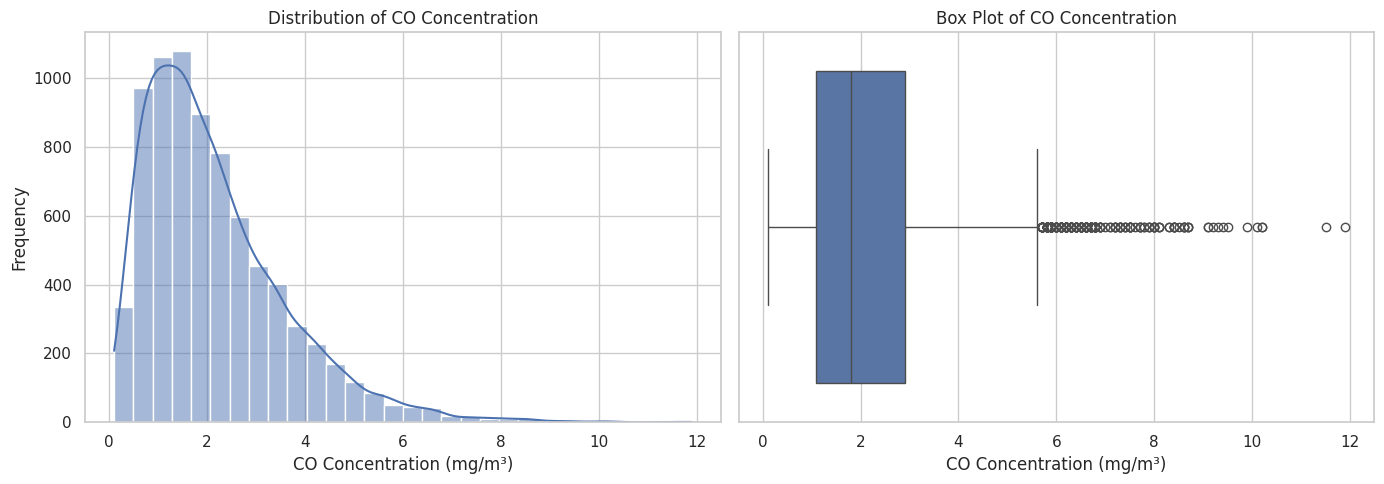

In [29]:
# Visualizing the distribution of CO concentration

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=eda_df,
    x='CO(GT)',
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribution of CO Concentration')
axes[0].set_xlabel('CO Concentration (mg/m³)')
axes[0].set_ylabel('Frequency')

# Box plot
sns.boxplot(
    data=eda_df,
    x='CO(GT)',
    ax=axes[1]
)

axes[1].set_title('Box Plot of CO Concentration')
axes[1].set_xlabel('CO Concentration (mg/m³)')

plt.tight_layout()
plt.savefig('CO_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

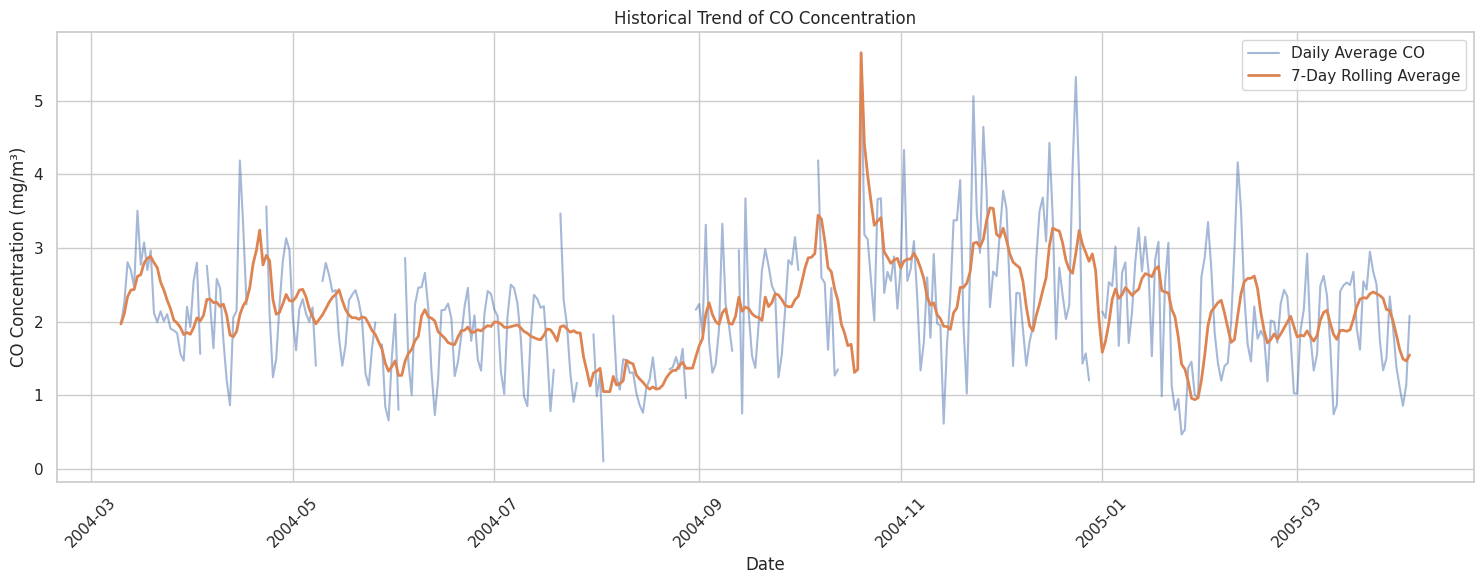

In [30]:
# Analyzing daily CO concentration over time

daily_co = (
    eda_df.set_index('DateTime')['CO(GT)']
    .resample('D')
    .mean()
)

# Calculating seven-day rolling average
rolling_co = daily_co.rolling(
    window=7,
    min_periods=1
).mean()

# Plotting the time-series trend
plt.figure(figsize=(15, 6))

plt.plot(
    daily_co.index,
    daily_co.values,
    alpha=0.5,
    label='Daily Average CO'
)

plt.plot(
    rolling_co.index,
    rolling_co.values,
    linewidth=2,
    label='7-Day Rolling Average'
)

plt.title('Historical Trend of CO Concentration')
plt.xlabel('Date')
plt.ylabel('CO Concentration (mg/m³)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('CO_Time_Trend.png', dpi=300, bbox_inches='tight')
plt.show()

In [31]:
# Calculating monthly CO concentration statistics

monthly_co = (
    eda_df.groupby(
        eda_df['DateTime'].dt.to_period('M')
    )['CO(GT)']
    .agg(['mean', 'median', 'count'])
)

monthly_co.index = monthly_co.index.astype(str)

monthly_co.columns = [
    'Average CO',
    'Median CO',
    'Number of Observations'
]

print("Monthly CO Concentration Statistics:")

display(monthly_co.round(3))

Monthly CO Concentration Statistics:


,Average CO,Median CO,Number of Observations
DateTime,,,
2004-03,2.292,2.10,492
2004-04,2.304,2.00,495
2004-05,1.940,1.80,592
2004-06,1.900,1.70,644
2004-07,1.785,1.60,558
2004-08,1.280,1.20,477
2004-09,2.164,1.85,556
2004-10,2.725,2.50,393
2004-11,2.685,2.30,679


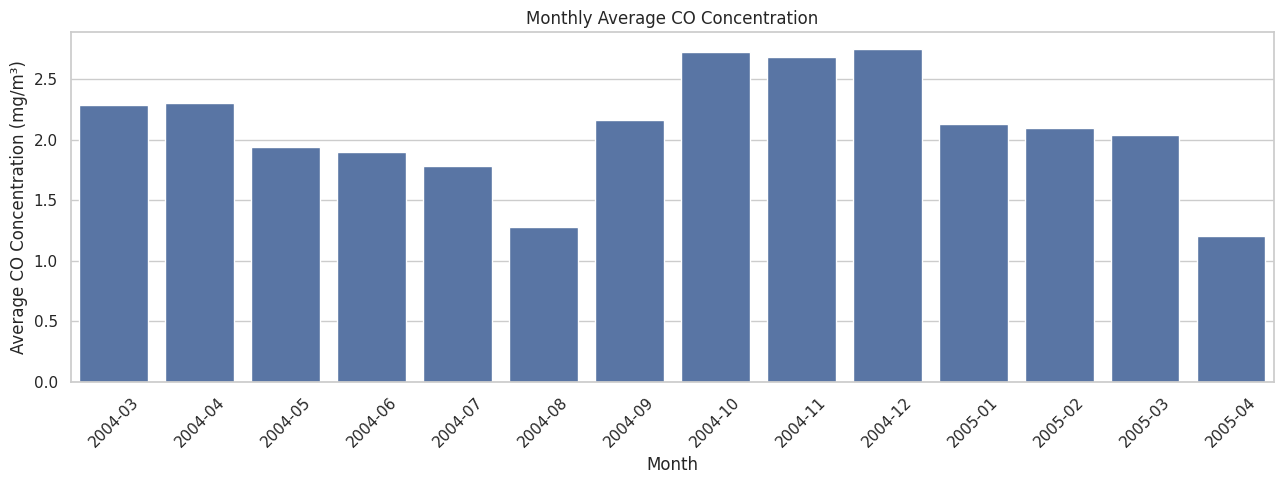

In [32]:
# Visualizing monthly average CO concentration

plt.figure(figsize=(13, 5))

sns.barplot(
    x=monthly_co.index,
    y=monthly_co['Average CO']
)

plt.title('Monthly Average CO Concentration')
plt.xlabel('Month')
plt.ylabel('Average CO Concentration (mg/m³)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('CO_Monthly_Average.png', dpi=300, bbox_inches='tight')
plt.show()

In [33]:
# Calculating the correlation matrix

correlation_data = eda_df[
    feature_columns + ['CO(GT)']
]

correlation_matrix = correlation_data.corr(
    method='pearson'
)

print("Correlation Matrix:")
display(correlation_matrix.round(3))

Correlation Matrix:


,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,CO(GT)
PT08.S1(CO),1.000,0.888,-0.765,0.674,0.898,0.029,0.152,0.136,0.879
PT08.S2(NMHC),0.888,1.000,-0.785,0.772,0.877,0.228,-0.061,0.193,0.916
PT08.S3(NOx),-0.765,-0.785,1.000,-0.514,-0.794,-0.108,-0.096,-0.215,-0.703
PT08.S4(NO2),0.674,0.772,-0.514,1.000,0.575,0.566,-0.020,0.641,0.631
PT08.S5(O3),0.898,0.877,-0.794,0.575,1.000,-0.045,0.153,0.067,0.854
T,0.029,0.228,-0.108,0.566,-0.045,1.000,-0.570,0.662,0.022
RH,0.152,-0.061,-0.096,-0.020,0.153,-0.570,1.000,0.171,0.049
AH,0.136,0.193,-0.215,0.641,0.067,0.662,0.171,1.000,0.049
CO(GT),0.879,0.916,-0.703,0.631,0.854,0.022,0.049,0.049,1.000


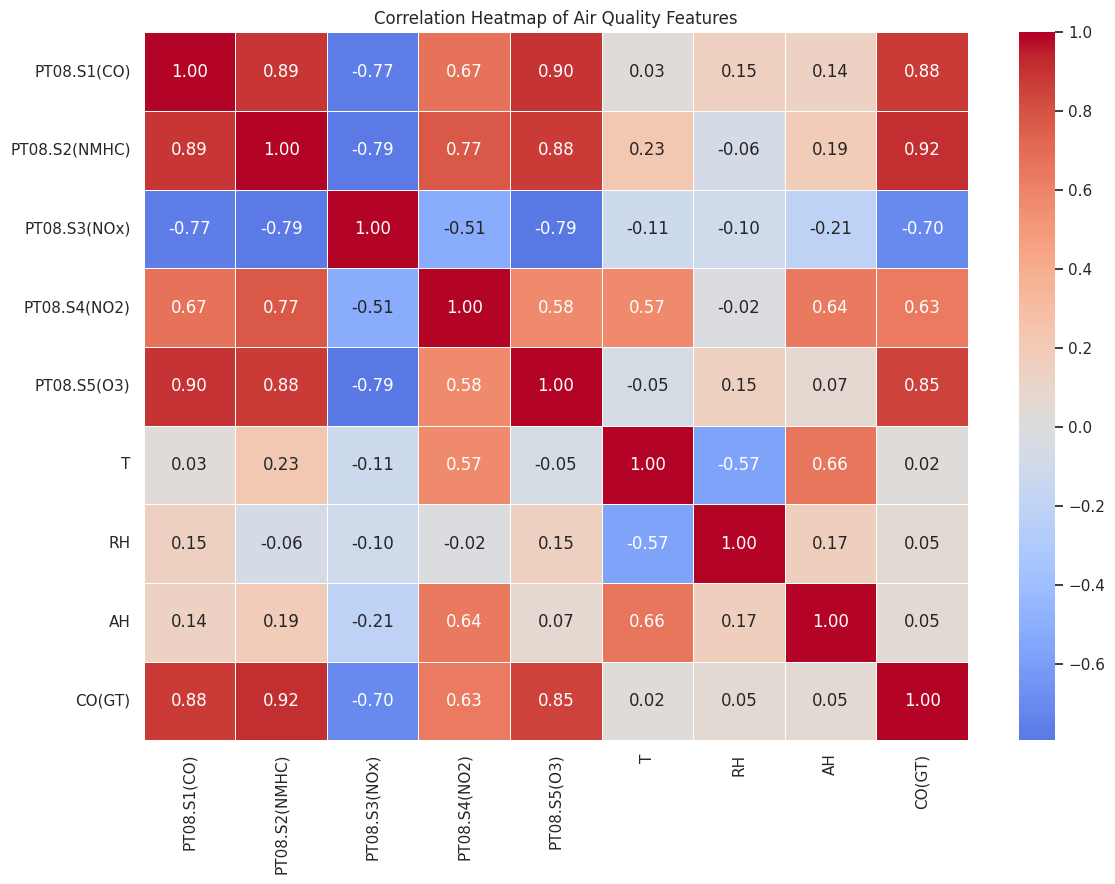

In [34]:
# Visualizing correlations using a heatmap

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Air Quality Features')
plt.tight_layout()

plt.savefig(
    'CO_Correlation_Heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

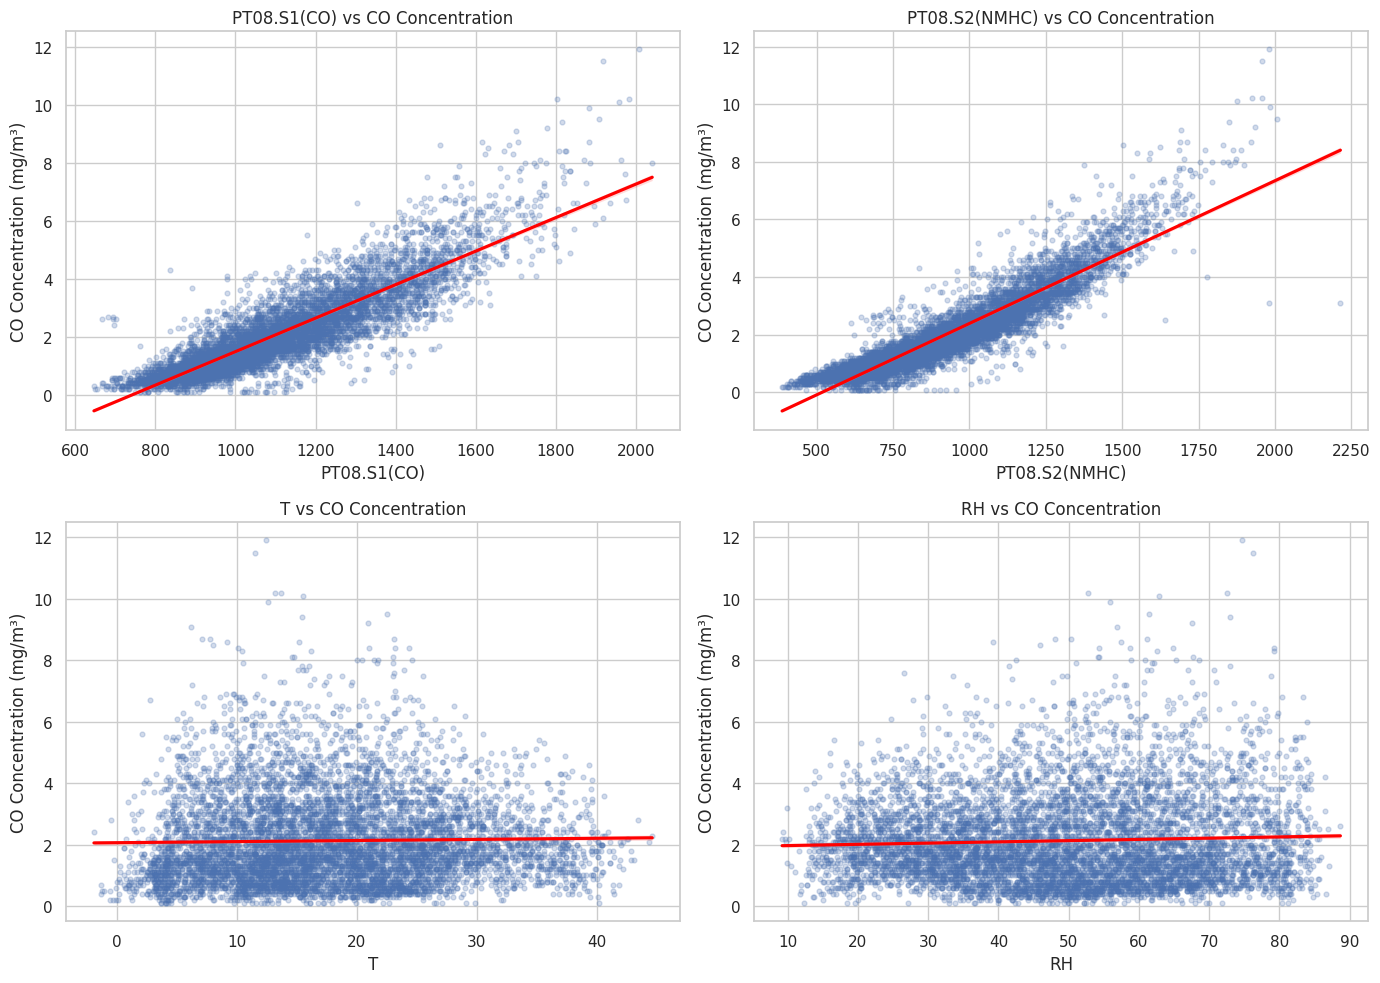

In [35]:
# Visualizing relationships between selected features and CO

selected_features = [
    'PT08.S1(CO)',
    'PT08.S2(NMHC)',
    'T',
    'RH'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(selected_features, axes.flatten()):

    plot_data = eda_df[
        [feature, 'CO(GT)']
    ].dropna()

    sns.regplot(
        data=plot_data,
        x=feature,
        y='CO(GT)',
        ax=ax,
        scatter_kws={'alpha': 0.25, 's': 12},
        line_kws={'color': 'red'}
    )

    ax.set_title(f'{feature} vs CO Concentration')
    ax.set_ylabel('CO Concentration (mg/m³)')

plt.tight_layout()

plt.savefig(
    'CO_Feature_Relationships.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [36]:
# Identifying the strongest correlations with CO

target_correlations = (
    correlation_matrix['CO(GT)']
    .drop('CO(GT)')
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False
    )
)

print("Features ranked by correlation with CO(GT):")

display(
    target_correlations.to_frame(
        name='Correlation with CO'
    ).round(3)
)

print("\nMost strongly correlated feature:",
      target_correlations.index[0])

print("Correlation value:",
      round(target_correlations.iloc[0], 3))

Features ranked by correlation with CO(GT):


,Correlation with CO
PT08.S2(NMHC),0.916
PT08.S1(CO),0.879
PT08.S5(O3),0.854
PT08.S3(NOx),-0.703
PT08.S4(NO2),0.631
RH,0.049
AH,0.049
T,0.022



Most strongly correlated feature: PT08.S2(NMHC)
Correlation value: 0.916


In [37]:
# Saving Exploratory Data Analysis results

co_summary.to_csv('CO_Descriptive_Statistics.csv')

monthly_co.to_csv('CO_Monthly_Statistics.csv')

correlation_matrix.to_csv('CO_Correlation_Matrix.csv')

print("EDA summary files saved successfully!")

print("\nSaved files:")
print("1. CO_Descriptive_Statistics.csv")
print("2. CO_Monthly_Statistics.csv")
print("3. CO_Correlation_Matrix.csv")

print("\nVisualization files:")
print("1. CO_Distribution.png")
print("2. CO_Time_Trend.png")
print("3. CO_Monthly_Average.png")
print("4. CO_Correlation_Heatmap.png")
print("5. CO_Feature_Relationships.png")

EDA summary files saved successfully!

Saved files:
1. CO_Descriptive_Statistics.csv
2. CO_Monthly_Statistics.csv
3. CO_Correlation_Matrix.csv

Visualization files:
1. CO_Distribution.png
2. CO_Time_Trend.png
3. CO_Monthly_Average.png
4. CO_Correlation_Heatmap.png
5. CO_Feature_Relationships.png


In [38]:
print("1. CO DESCRIPTIVE STATISTICS")
display(co_summary.round(3))

print("\n2. MONTHLY CO STATISTICS")
display(monthly_co.round(3))

print("\n3. CORRELATION MATRIX")
display(correlation_matrix.round(3))

print("\n4. FEATURES RANKED BY CORRELATION WITH CO")
display(target_correlations.to_frame(
    name='Correlation with CO'
).round(3))

1. CO DESCRIPTIVE STATISTICS


,CO(GT)
count,7674.000
mean,2.153
std,1.453
min,0.100
25%,1.100
50%,1.800
75%,2.900
max,11.900



2. MONTHLY CO STATISTICS


,Average CO,Median CO,Number of Observations
DateTime,,,
2004-03,2.292,2.10,492
2004-04,2.304,2.00,495
2004-05,1.940,1.80,592
2004-06,1.900,1.70,644
2004-07,1.785,1.60,558
2004-08,1.280,1.20,477
2004-09,2.164,1.85,556
2004-10,2.725,2.50,393
2004-11,2.685,2.30,679



3. CORRELATION MATRIX


,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,CO(GT)
PT08.S1(CO),1.000,0.888,-0.765,0.674,0.898,0.029,0.152,0.136,0.879
PT08.S2(NMHC),0.888,1.000,-0.785,0.772,0.877,0.228,-0.061,0.193,0.916
PT08.S3(NOx),-0.765,-0.785,1.000,-0.514,-0.794,-0.108,-0.096,-0.215,-0.703
PT08.S4(NO2),0.674,0.772,-0.514,1.000,0.575,0.566,-0.020,0.641,0.631
PT08.S5(O3),0.898,0.877,-0.794,0.575,1.000,-0.045,0.153,0.067,0.854
T,0.029,0.228,-0.108,0.566,-0.045,1.000,-0.570,0.662,0.022
RH,0.152,-0.061,-0.096,-0.020,0.153,-0.570,1.000,0.171,0.049
AH,0.136,0.193,-0.215,0.641,0.067,0.662,0.171,1.000,0.049
CO(GT),0.879,0.916,-0.703,0.631,0.854,0.022,0.049,0.049,1.000



4. FEATURES RANKED BY CORRELATION WITH CO


,Correlation with CO
PT08.S2(NMHC),0.916
PT08.S1(CO),0.879
PT08.S5(O3),0.854
PT08.S3(NOx),-0.703
PT08.S4(NO2),0.631
RH,0.049
AH,0.049
T,0.022


In [41]:
# Mounting Google Drive

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil
from pathlib import Path

# Creating a permanent project backup folder
backup_dir = Path(
    '/content/drive/MyDrive/CA2_Air_Quality_CO_Prediction/Phase_1_to_3_Outputs'
)

backup_dir.mkdir(parents=True, exist_ok=True)

# Files generated during Phases 1, 2 and 3
files_to_backup = [
    'AirQuality_Initial.csv',
    'AirQuality_Cleaned_Full.csv',
    'AirQuality_Modeling_Dataset.csv',
    'CO_Descriptive_Statistics.csv',
    'CO_Monthly_Statistics.csv',
    'CO_Correlation_Matrix.csv',
    'CO_Distribution.png',
    'CO_Time_Trend.png',
    'CO_Monthly_Average.png',
    'CO_Correlation_Heatmap.png',
    'CO_Feature_Relationships.png'
]

# Copying files to Google Drive
for filename in files_to_backup:

    source = Path('/content') / filename

    if source.exists():
        shutil.copy2(source, backup_dir / filename)
        print("Backed up:", filename)
    else:
        print("File not found:", filename)

print("\nBackup completed!")
print("Google Drive location:", backup_dir)

MessageError: Error: credential propagation was unsuccessful

In [42]:
# Creating a ZIP backup of all Phase 1, 2 and 3 deliverables

import os
import zipfile
from google.colab import files

files_to_backup = [
    'AirQuality_Initial.csv',
    'AirQuality_Cleaned_Full.csv',
    'AirQuality_Modeling_Dataset.csv',
    'CO_Descriptive_Statistics.csv',
    'CO_Monthly_Statistics.csv',
    'CO_Correlation_Matrix.csv',
    'CO_Distribution.png',
    'CO_Time_Trend.png',
    'CO_Monthly_Average.png',
    'CO_Correlation_Heatmap.png',
    'CO_Feature_Relationships.png'
]

zip_path = '/content/CA2_Air_Quality_Phase_1_to_3_Backup.zip'

missing_files = []

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zip_file:

    for filename in files_to_backup:

        filepath = '/content/' + filename

        if os.path.isfile(filepath):
            zip_file.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            missing_files.append(filename)
            print("Missing:", filename)

print("\nZIP backup created!")

print("Files included:", len(files_to_backup) - len(missing_files))
print("Missing files:", missing_files)

Added: AirQuality_Initial.csv
Added: AirQuality_Cleaned_Full.csv
Added: AirQuality_Modeling_Dataset.csv
Added: CO_Descriptive_Statistics.csv
Added: CO_Monthly_Statistics.csv
Added: CO_Correlation_Matrix.csv
Added: CO_Distribution.png
Added: CO_Time_Trend.png
Added: CO_Monthly_Average.png
Added: CO_Correlation_Heatmap.png
Added: CO_Feature_Relationships.png

ZIP backup created!
Files included: 11
Missing files: []


In [43]:
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Phase 4 — Machine Learning Model Development

In [44]:
# Importing machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

import numpy as np
import pandas as pd

import joblib

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [45]:
# Preparing input features and target variable

X = model_data[feature_columns].copy()

y = model_data['CO(GT)'].copy()

# Checking the prepared data

print("Input feature shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable: CO(GT)")

print("\nMissing values in target:", y.isna().sum())
print("Rows in modeling dataset:", len(model_data))

Input feature shape: (7674, 8)
Target variable shape: (7674,)

Input features:
['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Target variable: CO(GT)

Missing values in target: 0
Rows in modeling dataset: 7674


In [46]:
# Performing chronological train-test split

split_index = int(len(model_data) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Displaying split information

print("TRAINING AND TESTING DATA SUMMARY")
print("-" * 40)

print("Total records:", len(model_data))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining period:")
print(model_data['DateTime'].iloc[0],
      "to",
      model_data['DateTime'].iloc[split_index - 1])

print("\nTesting period:")
print(model_data['DateTime'].iloc[split_index],
      "to",
      model_data['DateTime'].iloc[-1])

print("\nTraining order preserved:",
      model_data['DateTime'].iloc[:split_index].is_monotonic_increasing)

print("Testing order preserved:",
      model_data['DateTime'].iloc[split_index:].is_monotonic_increasing)

TRAINING AND TESTING DATA SUMMARY
----------------------------------------
Total records: 7674
Training records: 6139
Testing records: 1535

Training data shape: (6139, 8)
Testing data shape: (1535, 8)

Training period:
2004-03-10 18:00:00 to 2005-01-29 06:00:00

Testing period:
2005-01-29 07:00:00 to 2005-04-04 14:00:00

Training order preserved: True
Testing order preserved: True


In [47]:
# Creating the Linear Regression pipeline

linear_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', LinearRegression())
])

print("Linear Regression pipeline created successfully!")

Linear Regression pipeline created successfully!


In [48]:
# Creating the Decision Tree Regression pipeline

decision_tree_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

print("Decision Tree Regression pipeline created successfully!")

Decision Tree Regression pipeline created successfully!


In [49]:
# Training the Linear Regression model

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [50]:
# Training the Decision Tree Regression model

decision_tree_model.fit(X_train, y_train)

print("Decision Tree Regression model trained successfully!")

Decision Tree Regression model trained successfully!


In [51]:
# Generating Linear Regression predictions

y_train_pred_lr = linear_model.predict(X_train)
y_test_pred_lr = linear_model.predict(X_test)

# Generating Decision Tree Regression predictions

y_train_pred_dt = decision_tree_model.predict(X_train)
y_test_pred_dt = decision_tree_model.predict(X_test)

print("Predictions generated successfully!")

print("\nLinear Regression:")
print("Training predictions:", len(y_train_pred_lr))
print("Testing predictions:", len(y_test_pred_lr))

print("\nDecision Tree Regression:")
print("Training predictions:", len(y_train_pred_dt))
print("Testing predictions:", len(y_test_pred_dt))

Predictions generated successfully!

Linear Regression:
Training predictions: 6139
Testing predictions: 1535

Decision Tree Regression:
Training predictions: 6139
Testing predictions: 1535


In [52]:
# Comparing actual and predicted CO concentrations

test_results = pd.DataFrame({
    'DateTime': model_data['DateTime'].iloc[split_index:].values,
    'Actual_CO': y_test.values,
    'Linear_Regression_Predicted_CO': y_test_pred_lr,
    'Decision_Tree_Predicted_CO': y_test_pred_dt
})

print("Actual vs Predicted CO Concentrations:")
display(test_results.head(10).round(3))

Actual vs Predicted CO Concentrations:


,DateTime,Actual_CO,Linear_Regression_Predicted_CO,Decision_Tree_Predicted_CO
0,2005-01-29 07:00:00,0.5,0.334,0.6
1,2005-01-29 08:00:00,0.8,0.731,0.6
2,2005-01-29 09:00:00,1.1,0.920,1.1
3,2005-01-29 10:00:00,1.1,0.928,1.1
4,2005-01-29 11:00:00,1.1,0.982,1.3
5,2005-01-29 12:00:00,1.1,0.754,0.2
6,2005-01-29 13:00:00,1.1,0.795,1.1
7,2005-01-29 14:00:00,1.2,0.950,1.3
8,2005-01-29 15:00:00,1.0,0.727,0.2
9,2005-01-29 16:00:00,1.2,0.840,0.2


In [53]:
# Saving trained machine learning models

joblib.dump(
    linear_model,
    'Linear_Regression_Model.joblib'
)

joblib.dump(
    decision_tree_model,
    'Decision_Tree_Model.joblib'
)

# Saving testing predictions

test_results.to_csv(
    'CA2_Test_Predictions.csv',
    index=False
)

print("Machine learning models saved successfully!")

print("\nSaved files:")
print("1. Linear_Regression_Model.joblib")
print("2. Decision_Tree_Model.joblib")
print("3. CA2_Test_Predictions.csv")

Machine learning models saved successfully!

Saved files:
1. Linear_Regression_Model.joblib
2. Decision_Tree_Model.joblib
3. CA2_Test_Predictions.csv


In [54]:
# Final verification of Phase 4

print("PHASE 4 - FINAL VERIFICATION")
print("-" * 45)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nLinear Regression:")
print("Model fitted:", hasattr(linear_model, 'named_steps'))
print("Training predictions:", len(y_train_pred_lr))
print("Testing predictions:", len(y_test_pred_lr))

print("\nDecision Tree Regression:")
print("Model fitted:", hasattr(decision_tree_model, 'named_steps'))
print("Training predictions:", len(y_train_pred_dt))
print("Testing predictions:", len(y_test_pred_dt))

print("\nPrediction results shape:", test_results.shape)

print("\nAll models trained and predictions generated successfully!")

PHASE 4 - FINAL VERIFICATION
---------------------------------------------
Training records: 6139
Testing records: 1535

Linear Regression:
Model fitted: True
Training predictions: 6139
Testing predictions: 1535

Decision Tree Regression:
Model fitted: True
Training predictions: 6139
Testing predictions: 1535

Prediction results shape: (1535, 4)

All models trained and predictions generated successfully!


# Phase 5 — Model Evaluation and Performance Comparison

In [55]:
# Importing model evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [56]:
# Evaluating Linear Regression

lr_train_mae = mean_absolute_error(y_train, y_train_pred_lr)
lr_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_lr))
lr_train_r2 = r2_score(y_train, y_train_pred_lr)

lr_test_mae = mean_absolute_error(y_test, y_test_pred_lr)
lr_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))
lr_test_r2 = r2_score(y_test, y_test_pred_lr)


# Evaluating Decision Tree Regression

dt_train_mae = mean_absolute_error(y_train, y_train_pred_dt)
dt_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_dt))
dt_train_r2 = r2_score(y_train, y_train_pred_dt)

dt_test_mae = mean_absolute_error(y_test, y_test_pred_dt)
dt_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_dt))
dt_test_r2 = r2_score(y_test, y_test_pred_dt)

print("Evaluation metrics calculated successfully!")

Evaluation metrics calculated successfully!


In [57]:
# Comparing the performance of both models

model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree Regression'
    ],

    'Training MAE': [
        lr_train_mae,
        dt_train_mae
    ],

    'Testing MAE': [
        lr_test_mae,
        dt_test_mae
    ],

    'Training RMSE': [
        lr_train_rmse,
        dt_train_rmse
    ],

    'Testing RMSE': [
        lr_test_rmse,
        dt_test_rmse
    ],

    'Training R2': [
        lr_train_r2,
        dt_train_r2
    ],

    'Testing R2': [
        lr_test_r2,
        dt_test_r2
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(model_comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Training MAE,Testing MAE,Training RMSE,Testing RMSE,Training R2,Testing R2
0,Linear Regression,0.3613,0.3834,0.5983,0.6416,0.8358,0.7723
1,Decision Tree Regression,0.0536,0.5849,0.3423,0.8790,0.9463,0.5725


In [58]:
# Identifying the better-performing model

best_model_mae = model_comparison.loc[
    model_comparison['Testing MAE'].idxmin(), 'Model'
]

best_model_rmse = model_comparison.loc[
    model_comparison['Testing RMSE'].idxmin(), 'Model'
]

best_model_r2 = model_comparison.loc[
    model_comparison['Testing R2'].idxmax(), 'Model'
]

print("BEST MODEL BASED ON TESTING METRICS")
print("-----------------------------------")

print("Lowest MAE:", best_model_mae)
print("Lowest RMSE:", best_model_rmse)
print("Highest R2:", best_model_r2)

BEST MODEL BASED ON TESTING METRICS
-----------------------------------
Lowest MAE: Linear Regression
Lowest RMSE: Linear Regression
Highest R2: Linear Regression


In [59]:
# Saving model evaluation results

model_comparison.to_csv(
    'CA2_Model_Performance_Comparison.csv',
    index=False
)

print("Model performance comparison saved successfully!")

Model performance comparison saved successfully!


# Phase 6 — Final Result Visualizations and Model Analysis

In [60]:
# Preparing model predictions for visualization

results_plot = test_results.copy()

results_plot['DateTime'] = pd.to_datetime(
    results_plot['DateTime']
)

# Calculating prediction residuals
results_plot['LR_Residual'] = (
    results_plot['Actual_CO']
    - results_plot['Linear_Regression_Predicted_CO']
)

results_plot['DT_Residual'] = (
    results_plot['Actual_CO']
    - results_plot['Decision_Tree_Predicted_CO']
)

print("Visualization data prepared successfully!")
display(results_plot.head())

Visualization data prepared successfully!


,DateTime,Actual_CO,Linear_Regression_Predicted_CO,Decision_Tree_Predicted_CO,LR_Residual,DT_Residual
0,2005-01-29 07:00:00,0.5,0.334051,0.6,0.165949,-0.1
1,2005-01-29 08:00:00,0.8,0.731439,0.6,0.068561,0.2
2,2005-01-29 09:00:00,1.1,0.920393,1.1,0.179607,0.0
3,2005-01-29 10:00:00,1.1,0.927636,1.1,0.172364,0.0
4,2005-01-29 11:00:00,1.1,0.981724,1.3,0.118276,-0.2


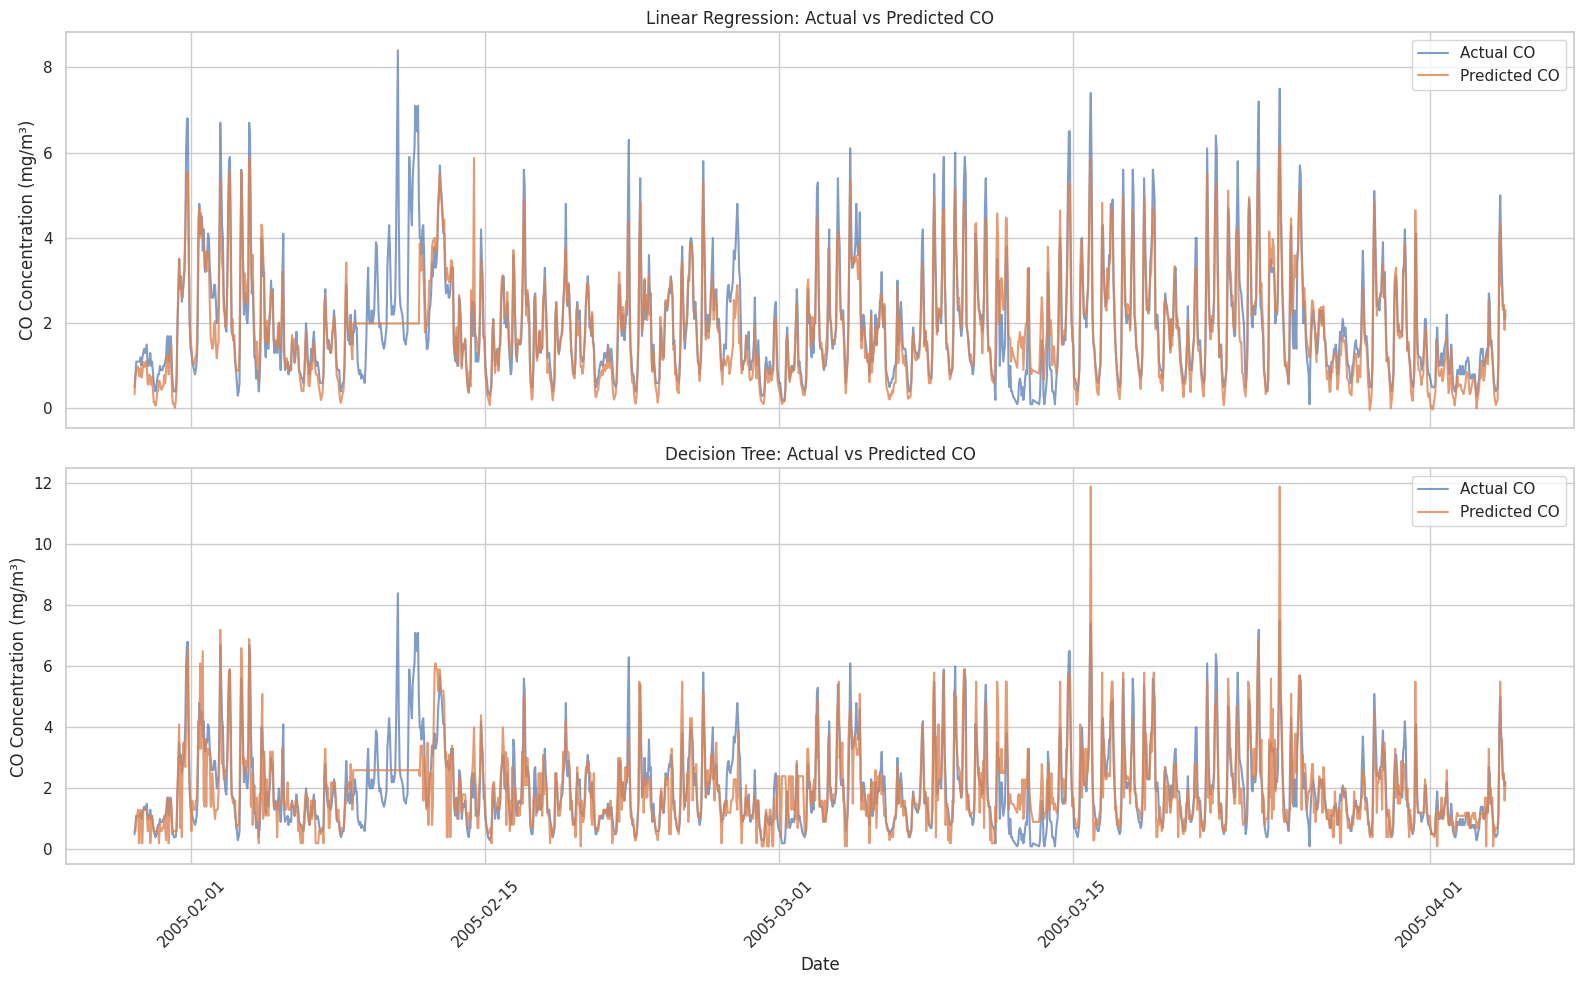

In [61]:
# Actual vs predicted CO concentrations over time

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Linear Regression
axes[0].plot(
    results_plot['DateTime'],
    results_plot['Actual_CO'],
    label='Actual CO',
    alpha=0.7
)

axes[0].plot(
    results_plot['DateTime'],
    results_plot['Linear_Regression_Predicted_CO'],
    label='Predicted CO',
    alpha=0.8
)

axes[0].set_title('Linear Regression: Actual vs Predicted CO')
axes[0].set_ylabel('CO Concentration (mg/m³)')
axes[0].legend()

# Decision Tree
axes[1].plot(
    results_plot['DateTime'],
    results_plot['Actual_CO'],
    label='Actual CO',
    alpha=0.7
)

axes[1].plot(
    results_plot['DateTime'],
    results_plot['Decision_Tree_Predicted_CO'],
    label='Predicted CO',
    alpha=0.8
)

axes[1].set_title('Decision Tree: Actual vs Predicted CO')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('CO Concentration (mg/m³)')
axes[1].legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'CO_Actual_vs_Predicted_Time.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

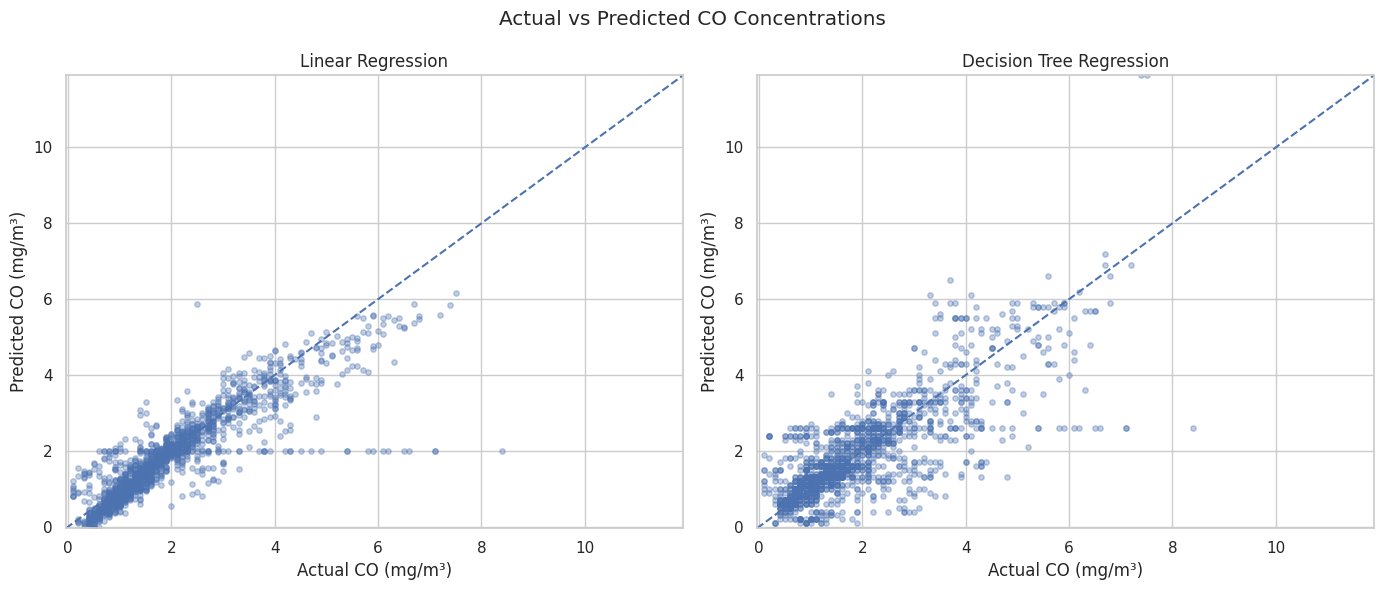

In [62]:
# Actual vs predicted scatter plots

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

actual = results_plot['Actual_CO']

lr_pred = results_plot['Linear_Regression_Predicted_CO']
dt_pred = results_plot['Decision_Tree_Predicted_CO']

min_value = min(actual.min(), lr_pred.min(), dt_pred.min())
max_value = max(actual.max(), lr_pred.max(), dt_pred.max())

# Linear Regression
axes[0].scatter(actual, lr_pred, alpha=0.35, s=15)

axes[0].plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

axes[0].set_title('Linear Regression')
axes[0].set_xlabel('Actual CO (mg/m³)')
axes[0].set_ylabel('Predicted CO (mg/m³)')

# Decision Tree
axes[1].scatter(actual, dt_pred, alpha=0.35, s=15)

axes[1].plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

axes[1].set_title('Decision Tree Regression')
axes[1].set_xlabel('Actual CO (mg/m³)')
axes[1].set_ylabel('Predicted CO (mg/m³)')

for ax in axes:
    ax.set_xlim(min_value, max_value)
    ax.set_ylim(min_value, max_value)

plt.suptitle('Actual vs Predicted CO Concentrations')
plt.tight_layout()

plt.savefig(
    'CO_Actual_vs_Predicted_Scatter.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

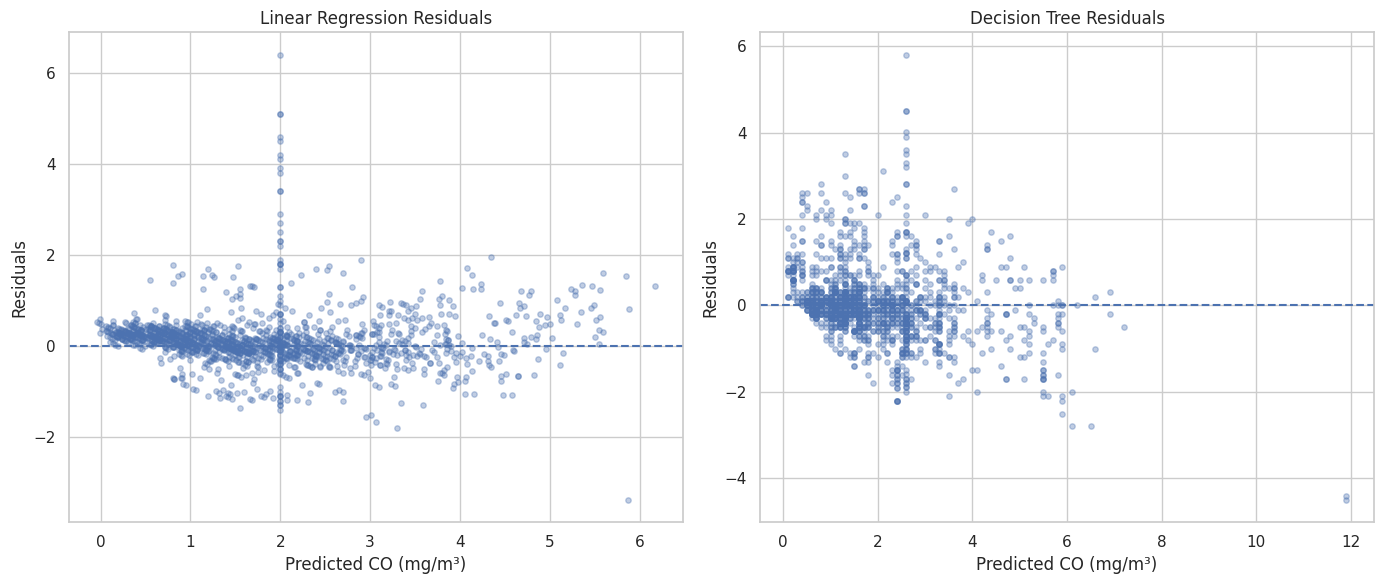

In [63]:
# Residual plots for both regression models

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Linear Regression residuals
axes[0].scatter(
    lr_pred,
    results_plot['LR_Residual'],
    alpha=0.35,
    s=15
)

axes[0].axhline(
    y=0,
    linestyle='--'
)

axes[0].set_title('Linear Regression Residuals')
axes[0].set_xlabel('Predicted CO (mg/m³)')
axes[0].set_ylabel('Residuals')

# Decision Tree residuals
axes[1].scatter(
    dt_pred,
    results_plot['DT_Residual'],
    alpha=0.35,
    s=15
)

axes[1].axhline(
    y=0,
    linestyle='--'
)

axes[1].set_title('Decision Tree Residuals')
axes[1].set_xlabel('Predicted CO (mg/m³)')
axes[1].set_ylabel('Residuals')

plt.tight_layout()

plt.savefig(
    'CO_Residual_Analysis.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

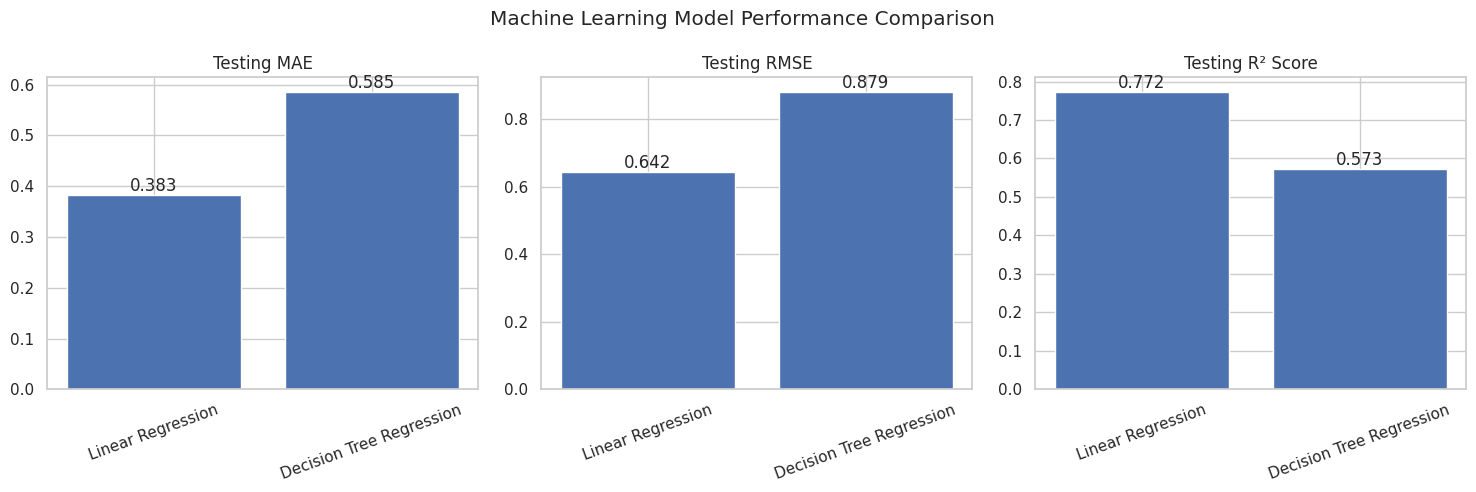

In [64]:
# Visual comparison of model performance

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

model_names = model_comparison['Model']

metrics = [
    ('Testing MAE', 'Testing MAE'),
    ('Testing RMSE', 'Testing RMSE'),
    ('Testing R2', 'Testing R² Score')
]

for ax, (column, title) in zip(axes, metrics):

    bars = ax.bar(
        model_names,
        model_comparison[column]
    )

    ax.set_title(title)
    ax.tick_params(axis='x', rotation=20)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f'{height:.3f}',
            ha='center',
            va='bottom'
        )

plt.suptitle('Machine Learning Model Performance Comparison')
plt.tight_layout()

plt.savefig(
    'CA2_Model_Performance_Chart.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [65]:
# Extracting Decision Tree feature importance

tree_regressor = decision_tree_model.named_steps['regressor']

feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': tree_regressor.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Decision Tree Feature Importance:")
display(feature_importance.round(4))

Decision Tree Feature Importance:


,Feature,Importance
1,PT08.S2(NMHC),0.8794
5,T,0.0337
0,PT08.S1(CO),0.0200
2,PT08.S3(NOx),0.0181
4,PT08.S5(O3),0.0150
3,PT08.S4(NO2),0.0124
6,RH,0.0116
7,AH,0.0097


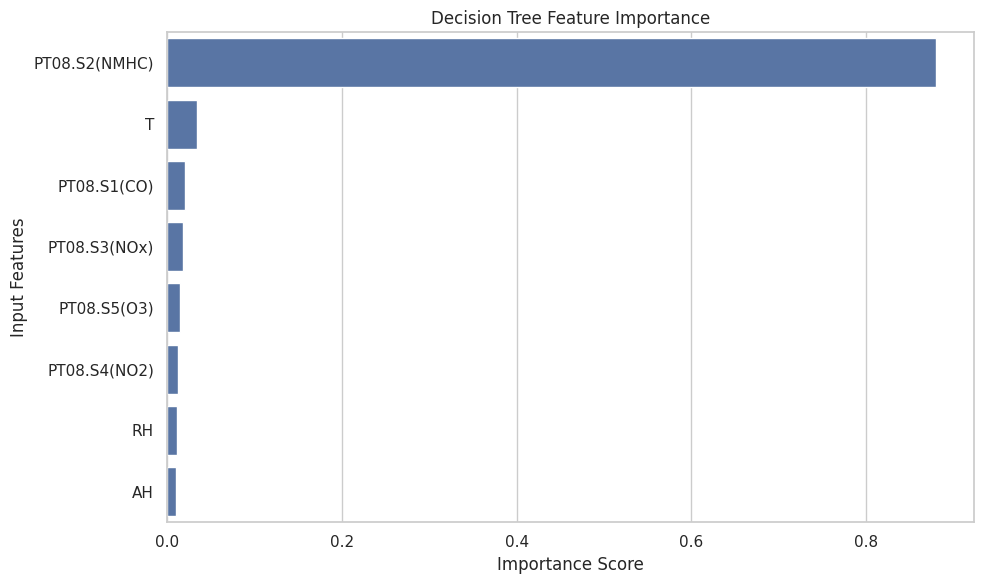

In [66]:
# Visualizing feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Decision Tree Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Input Features')
plt.tight_layout()

plt.savefig(
    'CA2_Feature_Importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [67]:
# Saving the final visualization data

results_plot.to_csv(
    'CA2_Final_Prediction_Results.csv',
    index=False
)

feature_importance.to_csv(
    'CA2_Decision_Tree_Feature_Importance.csv',
    index=False
)

print("Phase 6 visualization data saved successfully!")

Phase 6 visualization data saved successfully!


In [68]:
# Final Phase 6 verification

import os

phase6_files = [
    'CO_Actual_vs_Predicted_Time.png',
    'CO_Actual_vs_Predicted_Scatter.png',
    'CO_Residual_Analysis.png',
    'CA2_Model_Performance_Chart.png',
    'CA2_Feature_Importance.png',
    'CA2_Final_Prediction_Results.csv',
    'CA2_Decision_Tree_Feature_Importance.csv'
]

print("PHASE 6 - FINAL VERIFICATION")
print("-" * 45)

for filename in phase6_files:
    status = "Found" if os.path.exists(filename) else "Missing"
    print(filename, "—", status)

print("\nTotal files generated:",
      sum(os.path.exists(f) for f in phase6_files),
      "out of", len(phase6_files))

PHASE 6 - FINAL VERIFICATION
---------------------------------------------
CO_Actual_vs_Predicted_Time.png — Found
CO_Actual_vs_Predicted_Scatter.png — Found
CO_Residual_Analysis.png — Found
CA2_Model_Performance_Chart.png — Found
CA2_Feature_Importance.png — Found
CA2_Final_Prediction_Results.csv — Found
CA2_Decision_Tree_Feature_Importance.csv — Found

Total files generated: 7 out of 7


In [69]:
import os
import zipfile
from google.colab import files

# All project deliverables from Phases 1–6

backup_files = [
    # Phase 1 and 2
    'AirQuality_Initial.csv',
    'AirQuality_Cleaned_Full.csv',
    'AirQuality_Modeling_Dataset.csv',

    # Phase 3 - EDA
    'CO_Descriptive_Statistics.csv',
    'CO_Monthly_Statistics.csv',
    'CO_Correlation_Matrix.csv',
    'CO_Distribution.png',
    'CO_Time_Trend.png',
    'CO_Monthly_Average.png',
    'CO_Correlation_Heatmap.png',
    'CO_Feature_Relationships.png',

    # Phase 4 - Trained models
    'Linear_Regression_Model.joblib',
    'Decision_Tree_Model.joblib',
    'CA2_Test_Predictions.csv',

    # Phase 5 - Model evaluation
    'CA2_Model_Performance_Comparison.csv',

    # Phase 6 - Visualizations and results
    'CO_Actual_vs_Predicted_Time.png',
    'CO_Actual_vs_Predicted_Scatter.png',
    'CO_Residual_Analysis.png',
    'CA2_Model_Performance_Chart.png',
    'CA2_Feature_Importance.png',
    'CA2_Final_Prediction_Results.csv',
    'CA2_Decision_Tree_Feature_Importance.csv'
]

zip_path = '/content/CA2_Air_Quality_Phase_1_to_6_Backup.zip'

missing_files = []

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zip_file:

    for filename in backup_files:

        filepath = '/content/' + filename

        if os.path.isfile(filepath):
            zip_file.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            missing_files.append(filename)
            print("Missing:", filename)

print("\nBackup creation completed!")
print("Successfully included:", len(backup_files) - len(missing_files))
print("Missing files:", missing_files)

Added: AirQuality_Initial.csv
Added: AirQuality_Cleaned_Full.csv
Added: AirQuality_Modeling_Dataset.csv
Added: CO_Descriptive_Statistics.csv
Added: CO_Monthly_Statistics.csv
Added: CO_Correlation_Matrix.csv
Added: CO_Distribution.png
Added: CO_Time_Trend.png
Added: CO_Monthly_Average.png
Added: CO_Correlation_Heatmap.png
Added: CO_Feature_Relationships.png
Added: Linear_Regression_Model.joblib
Added: Decision_Tree_Model.joblib
Added: CA2_Test_Predictions.csv
Added: CA2_Model_Performance_Comparison.csv
Added: CO_Actual_vs_Predicted_Time.png
Added: CO_Actual_vs_Predicted_Scatter.png
Added: CO_Residual_Analysis.png
Added: CA2_Model_Performance_Chart.png
Added: CA2_Feature_Importance.png
Added: CA2_Final_Prediction_Results.csv
Added: CA2_Decision_Tree_Feature_Importance.csv

Backup creation completed!
Successfully included: 22
Missing files: []


In [70]:
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Phase 7 — Results Interpretation and Business Insights

In [71]:
# Displaying the feature importance results

print("DECISION TREE FEATURE IMPORTANCE")
print("-" * 40)

display(feature_importance.round(4))

print("\nMost important feature:",
      feature_importance.iloc[0]['Feature'])

print("Importance score:",
      round(feature_importance.iloc[0]['Importance'], 4))

DECISION TREE FEATURE IMPORTANCE
----------------------------------------


,Feature,Importance
1,PT08.S2(NMHC),0.8794
5,T,0.0337
0,PT08.S1(CO),0.0200
2,PT08.S3(NOx),0.0181
4,PT08.S5(O3),0.0150
3,PT08.S4(NO2),0.0124
6,RH,0.0116
7,AH,0.0097



Most important feature: PT08.S2(NMHC)
Importance score: 0.8794


In [72]:
# Comparing residual statistics

print("LINEAR REGRESSION RESIDUAL ANALYSIS")

display(
    results_plot['LR_Residual']
    .describe()
    .to_frame(name='Residual')
    .round(4)
)

print("\nDECISION TREE RESIDUAL ANALYSIS")

display(
    results_plot['DT_Residual']
    .describe()
    .to_frame(name='Residual')
    .round(4)
)

LINEAR REGRESSION RESIDUAL ANALYSIS


,Residual
count,1535.0000
mean,0.1331
std,0.6279
min,-3.3730
25%,-0.1236
50%,0.1078
75%,0.3075
max,6.4054



DECISION TREE RESIDUAL ANALYSIS


,Residual
count,1535.0000
mean,0.0327
std,0.8787
min,-4.5000
25%,-0.4000
50%,0.0000
75%,0.3000
max,5.8035


In [73]:
# Checking actual and predicted CO concentration ranges

prediction_summary = pd.DataFrame({
    'Actual CO': y_test,
    'Linear Regression': y_test_pred_lr,
    'Decision Tree': y_test_pred_dt
})

print("ACTUAL AND PREDICTED CO CONCENTRATION RANGES")

display(prediction_summary.describe().round(4))

ACTUAL AND PREDICTED CO CONCENTRATION RANGES


,Actual CO,Linear Regression,Decision Tree
count,1535.0000,1535.0000,1535.0000
mean,2.0021,1.8690,1.9695
std,1.3450,1.2027,1.3026
min,0.1000,-0.0394,0.1000
25%,1.0000,0.9432,1.1000
50%,1.6000,1.6715,1.6000
75%,2.6000,2.4989,2.5965
max,8.4000,6.1708,11.9000


### CO_Actual_vs_Predicted_Time.png

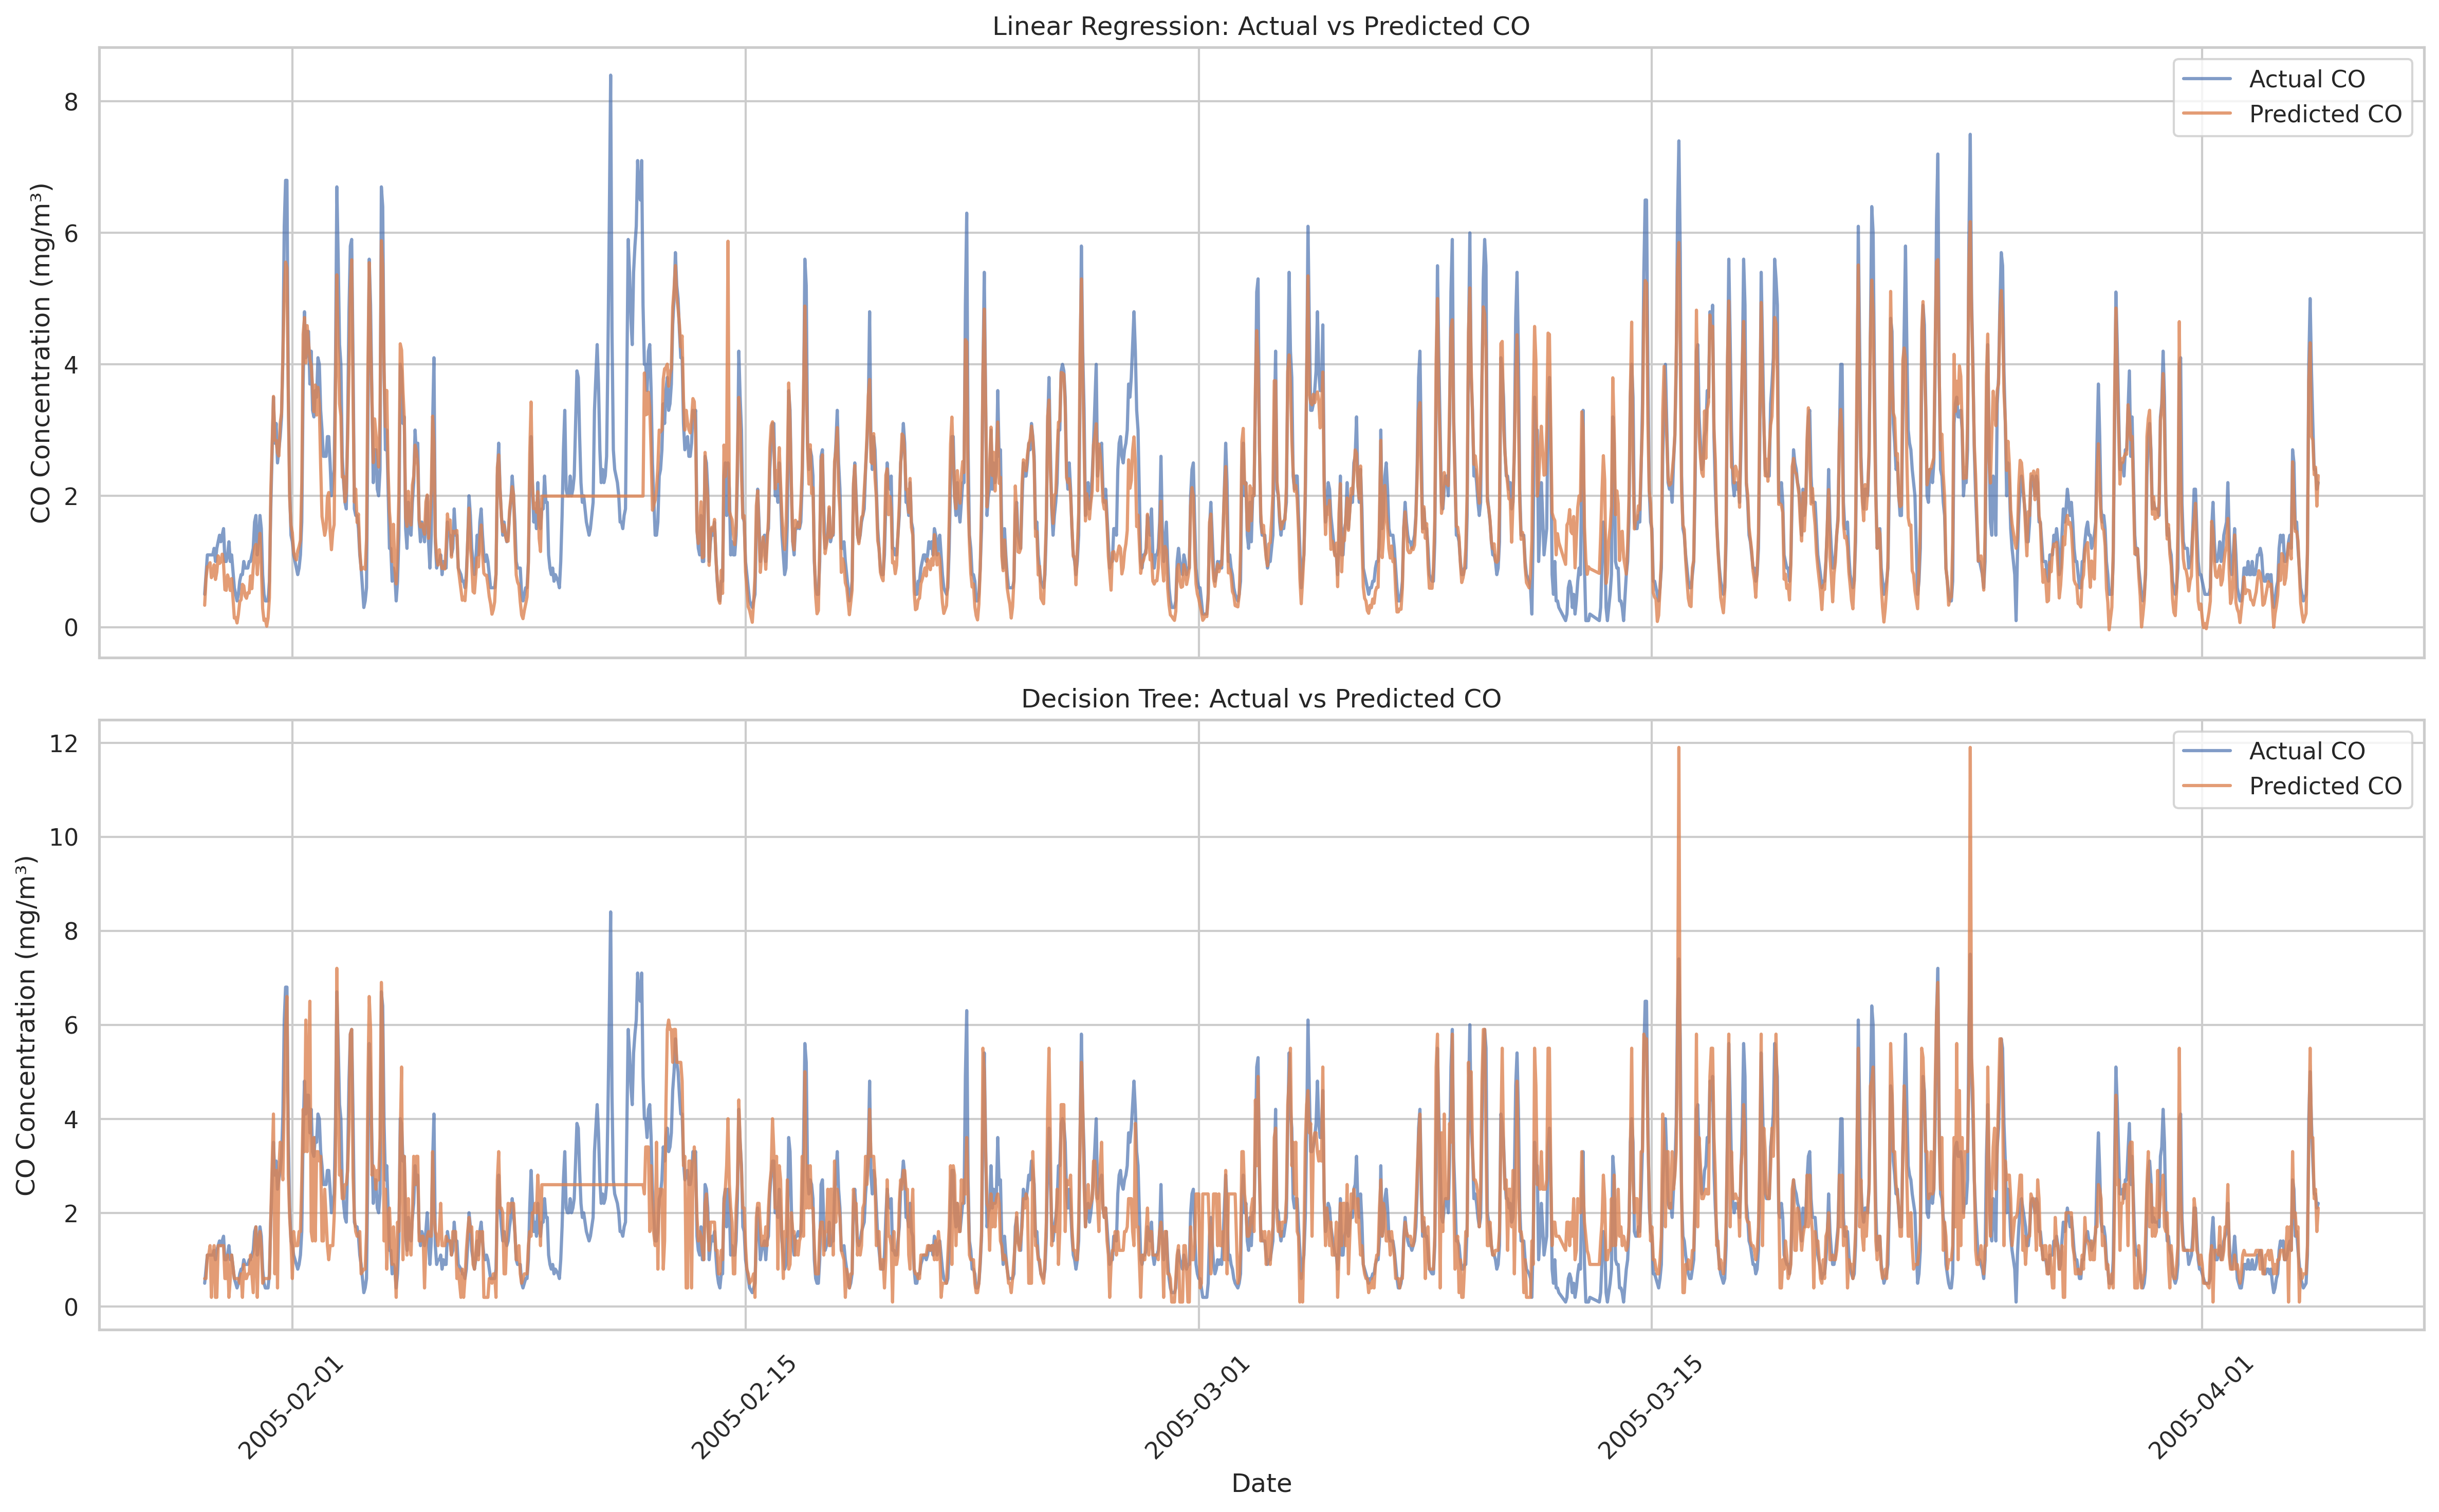

### CO_Actual_vs_Predicted_Scatter.png

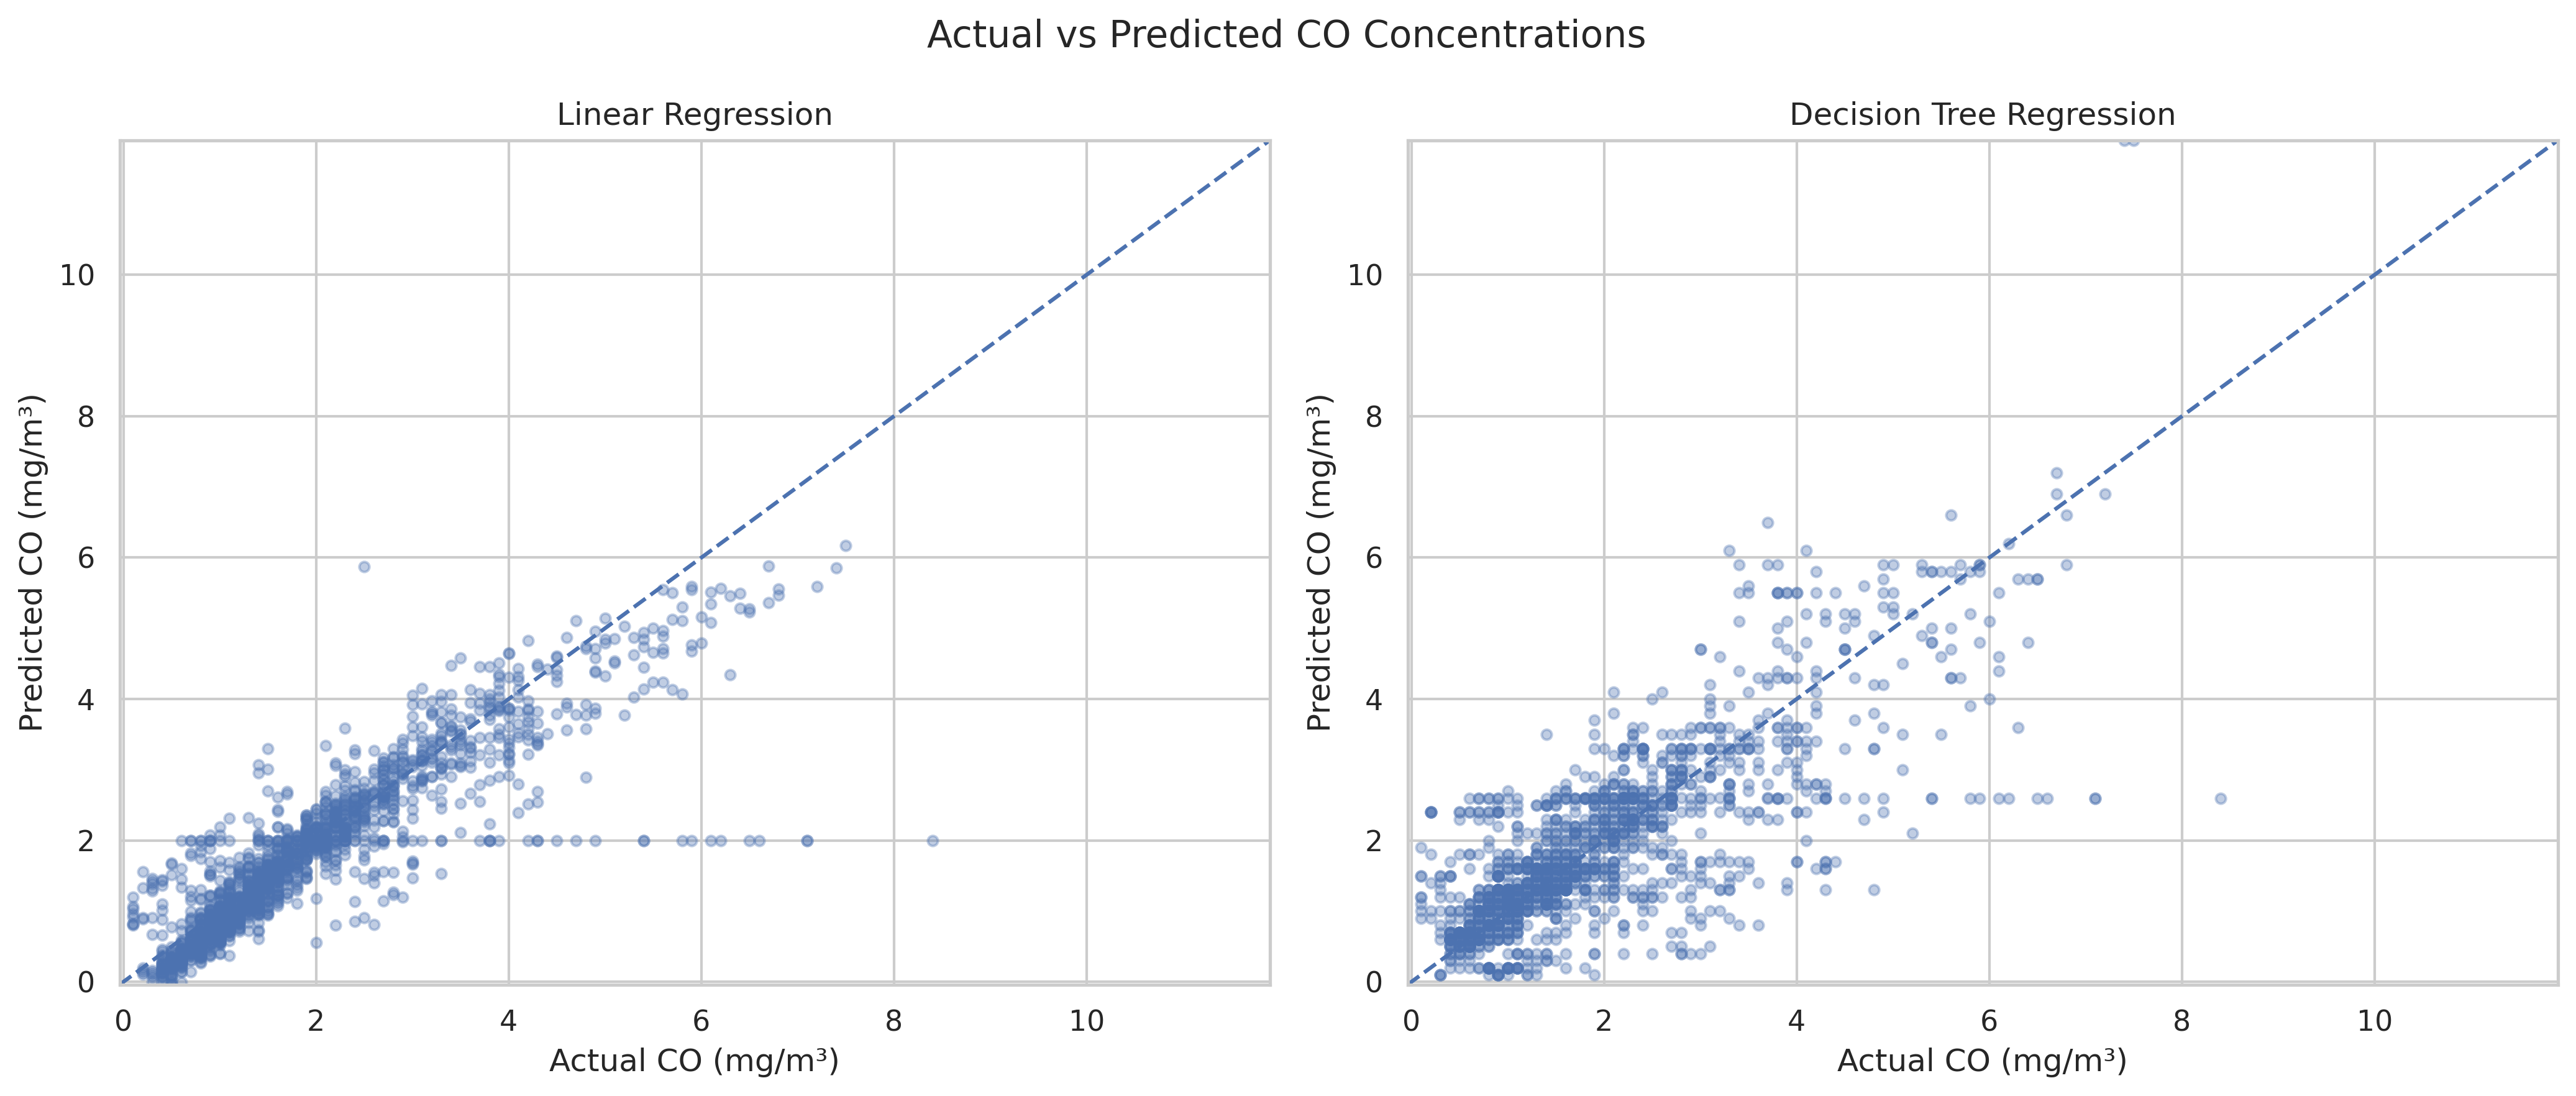

### CO_Residual_Analysis.png

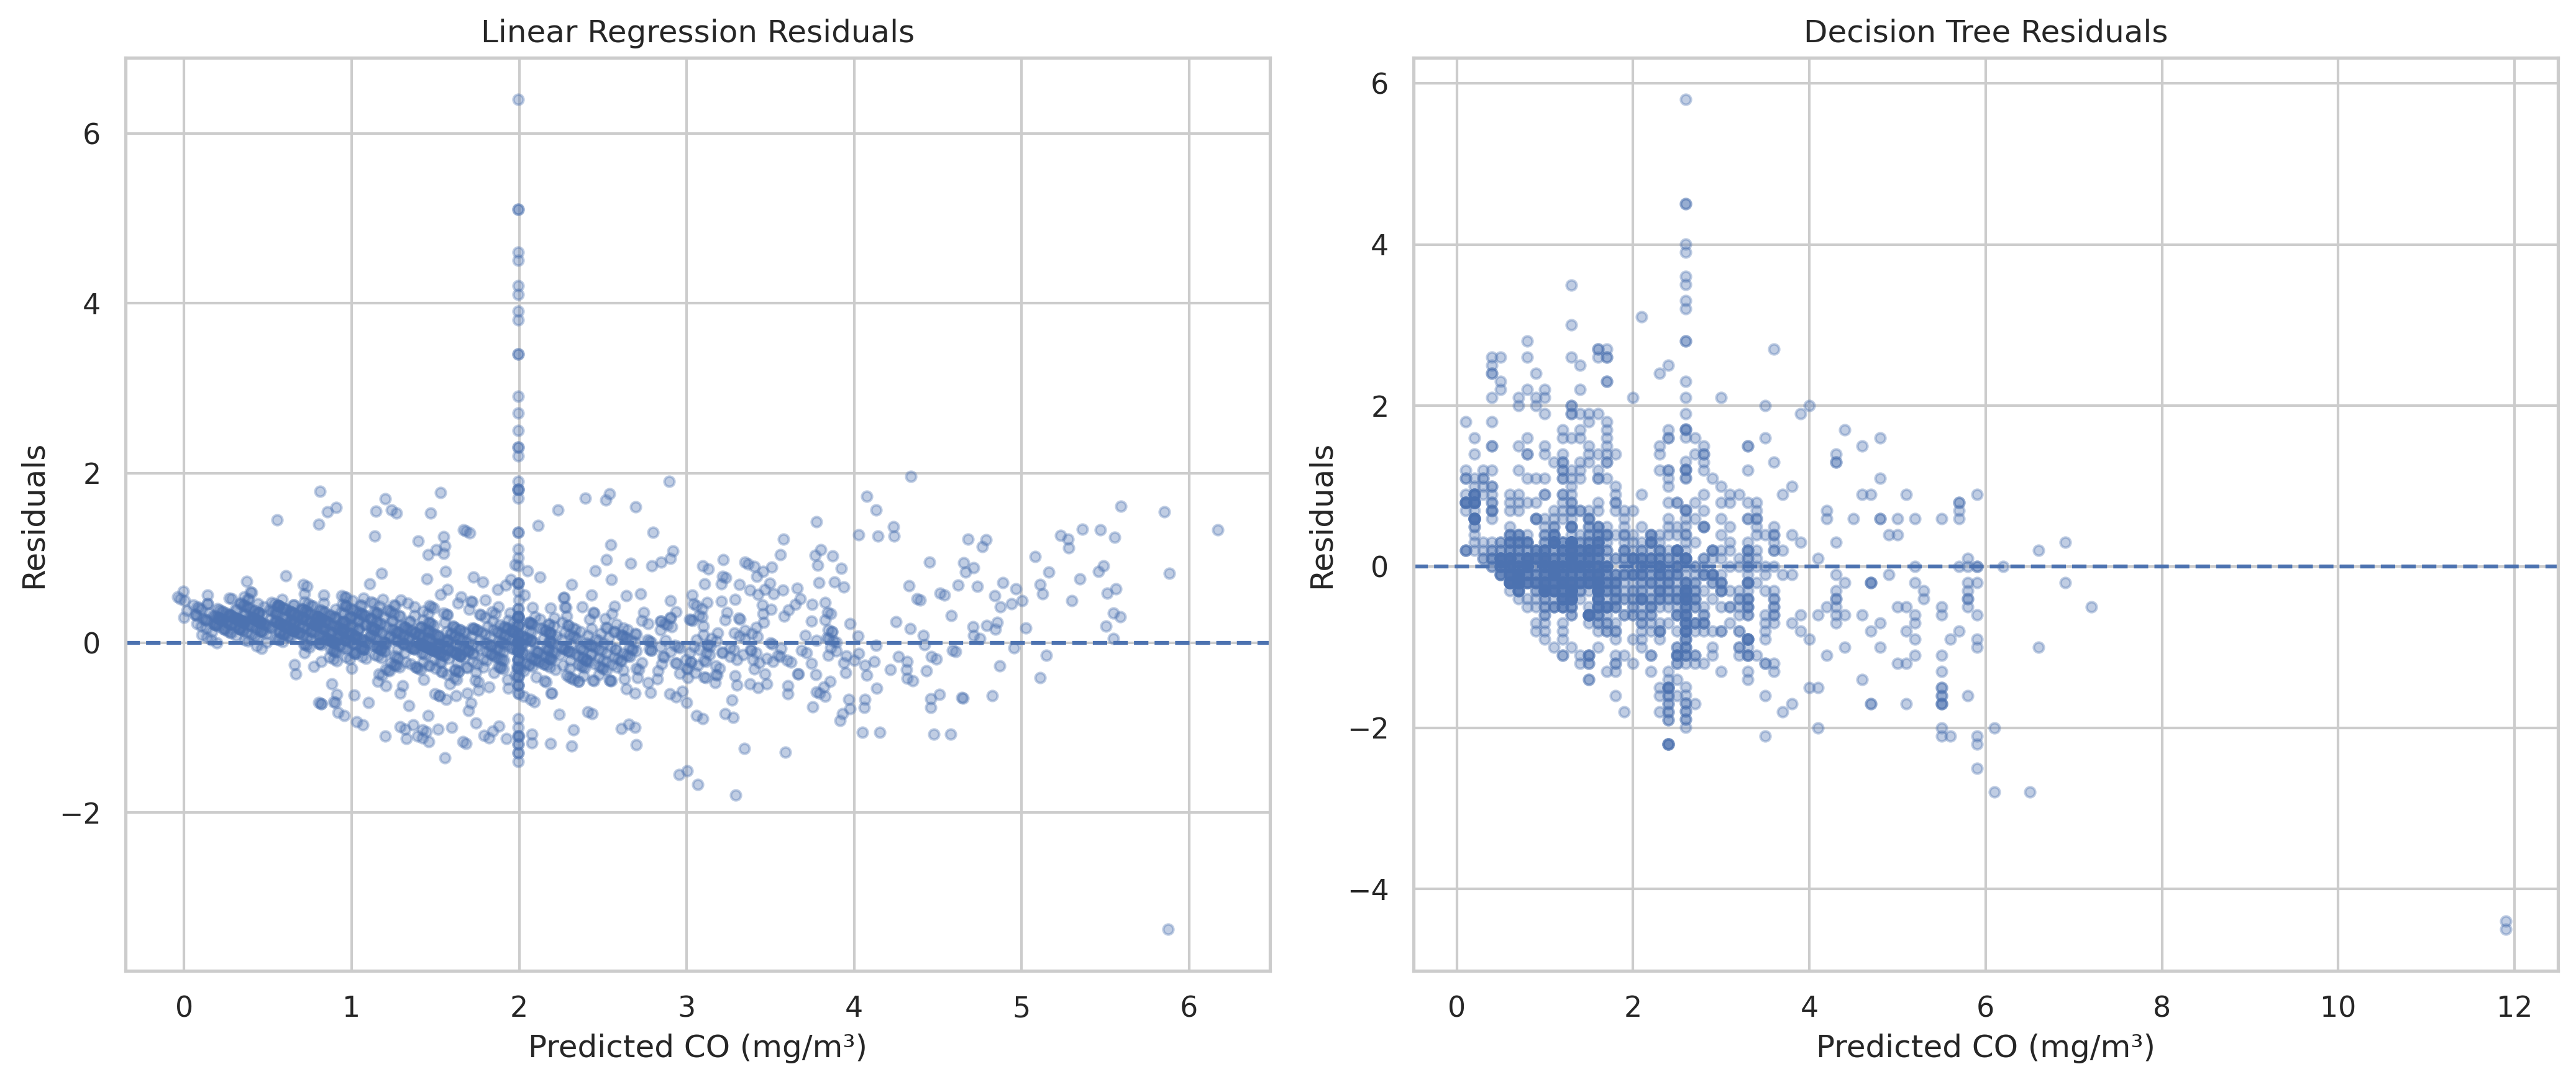

### CA2_Model_Performance_Chart.png

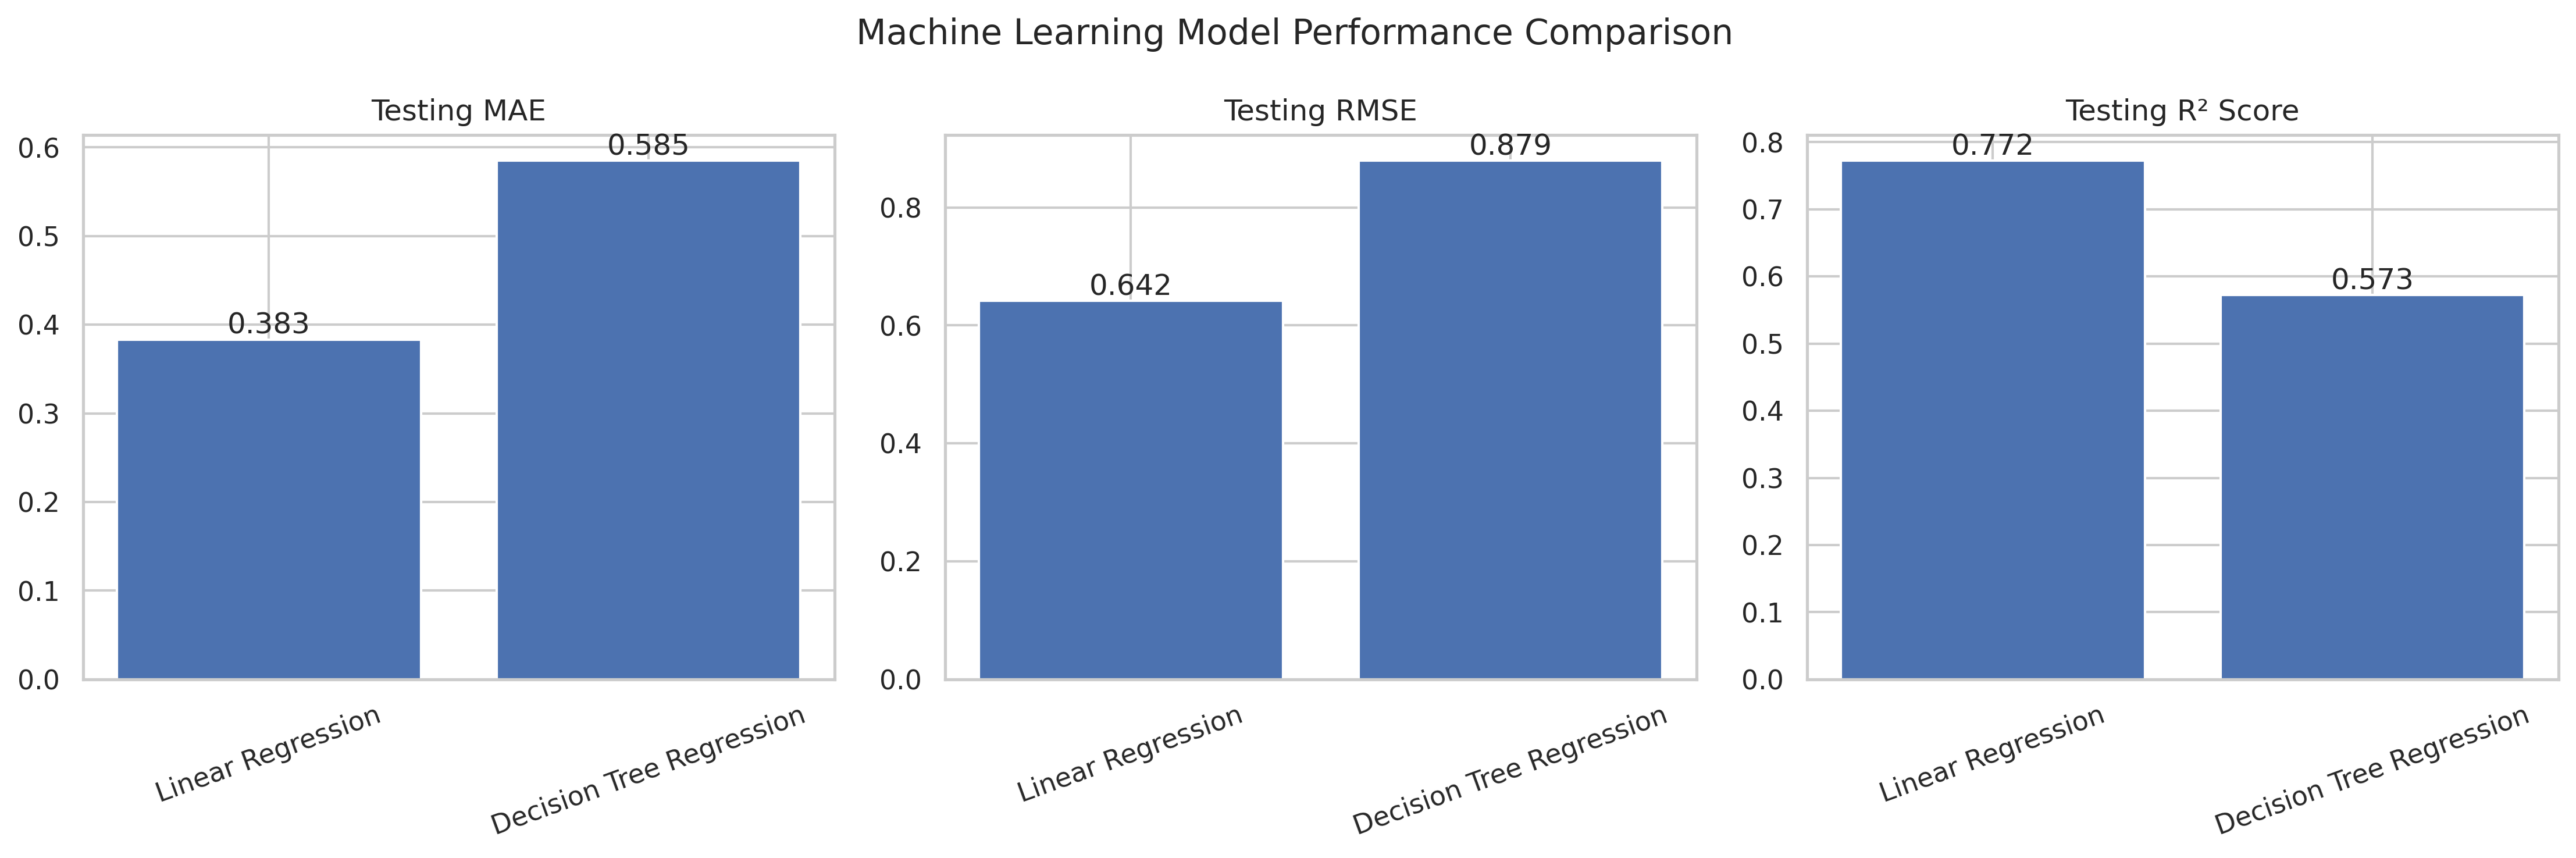

### CA2_Feature_Importance.png

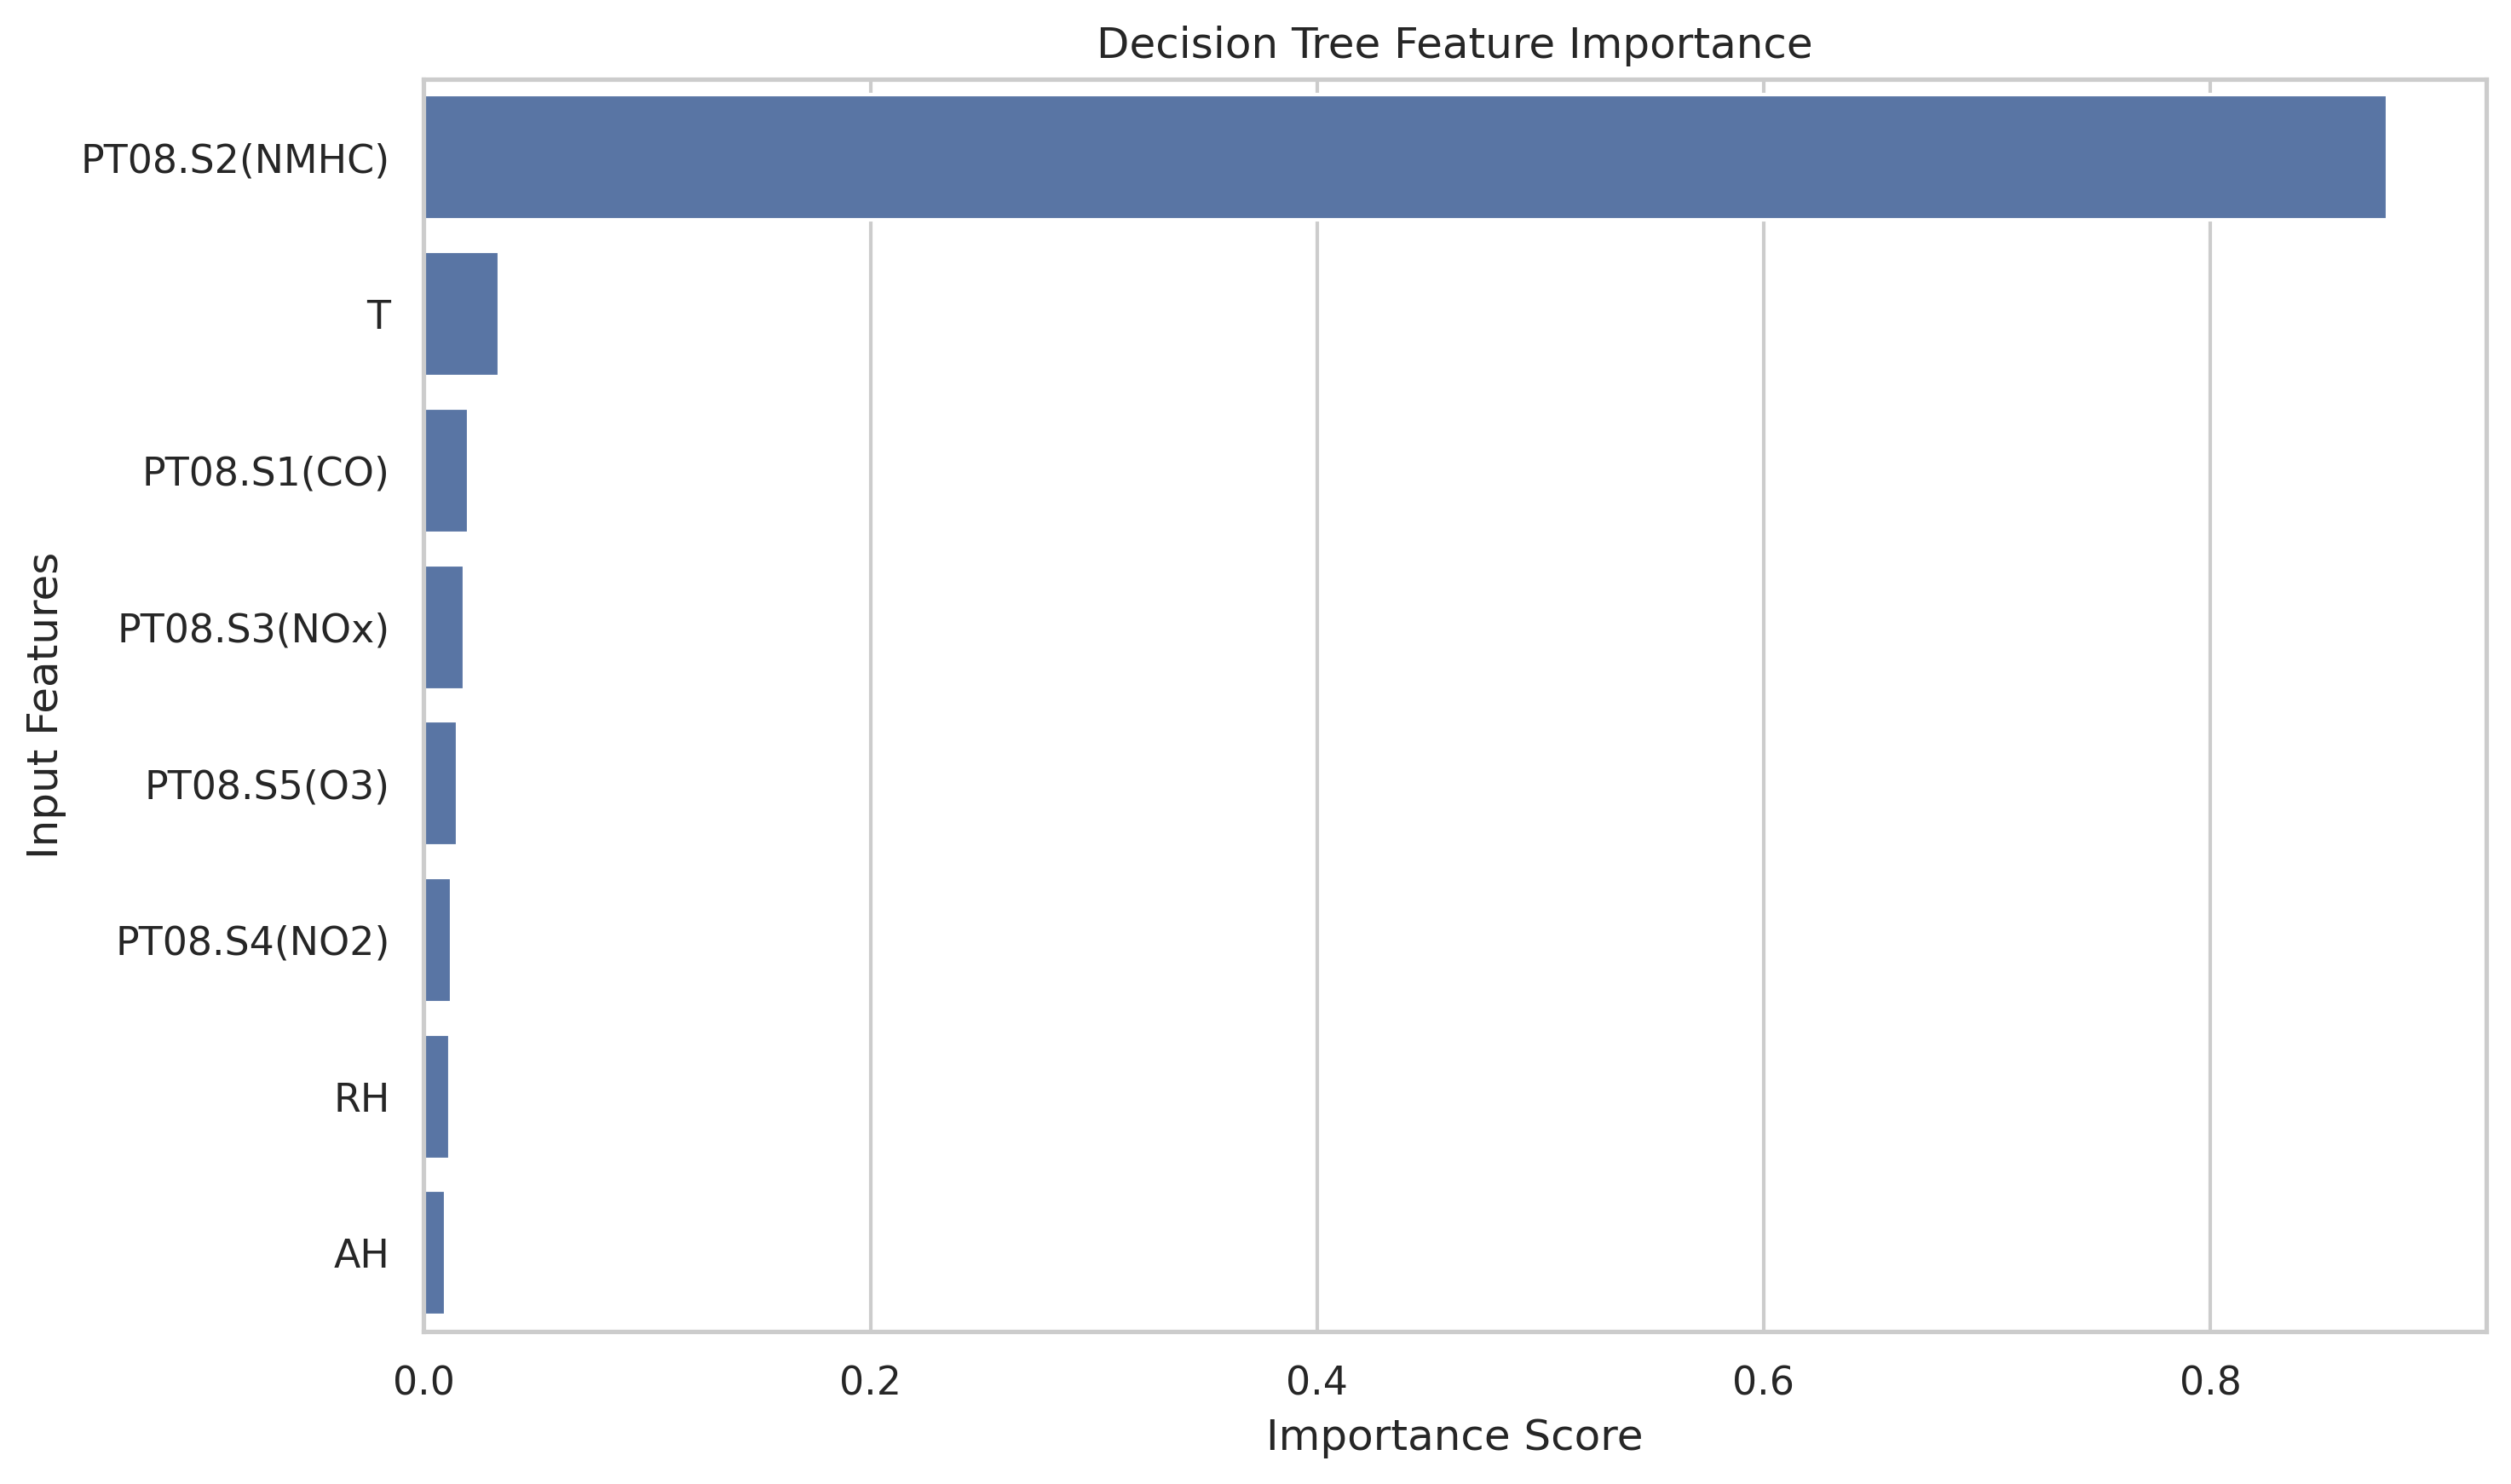

In [75]:
# Displaying all Phase 6 visualizations

from IPython.display import display, Image, Markdown
import os

visualization_files = [
    'CO_Actual_vs_Predicted_Time.png',
    'CO_Actual_vs_Predicted_Scatter.png',
    'CO_Residual_Analysis.png',
    'CA2_Model_Performance_Chart.png',
    'CA2_Feature_Importance.png'
]

for filename in visualization_files:

    display(Markdown(f"### {filename}"))

    if os.path.exists(filename):
        display(Image(filename=filename, width=1000))
    else:
        print("File not found:", filename)